## LOAD DATA

In [1]:
import pandas as pd
import numpy as np

data_file_path_test = "../data/mnist/mnist_test.csv"

df_test = pd.read_csv(data_file_path_test)

Y_test = df_test.iloc[:, 0].to_numpy()
x_test = df_test.iloc[:, 1:].to_numpy()

print(x_test.shape, Y_test.shape)

(9999, 784) (9999,)


In [2]:
x_test_grouped = []
Y_test_grouped = []

for label in range(10):
    indices = np.where(Y_test == label)[0][:100]

    x_test_grouped.append(x_test[indices])
    Y_test_grouped.append(Y_test[indices])

x_test_grouped = np.concatenate(x_test_grouped, axis=0)
Y_test_grouped = np.concatenate(Y_test_grouped, axis=0)

print(x_test_grouped.shape)
print(Y_test_grouped.shape)

(1000, 784)
(1000,)


In [3]:
x_all_data = x_test_grouped.reshape(1000, 1, 28, 28)
x_all_data.shape

(1000, 1, 28, 28)

## PYTHON MODEL REFRENCE DEFENITION

In [4]:
import json 
import os
import numpy as np 

path = "../params"

files = os.listdir(path=path)

print(files)

json_file = None

with open(os.path.join(path, "model_results.json"), 'r', encoding='utf-8') as f:
    json_file = json.load(f)

['softmax-10-bias.npz', 'neural-9-weights.npz', 'conv2d-1-bias.npz', 'pool-2-bias.npz', 'conv2d-3-weights.npz', 'conv2d-3-bias.npz', 'model_results.json', 'pool-6-bias.npz', '.gitignore', 'conv2d-5-weights.npz', 'neural-8-bias.npz', 'pool-6-weights.npz', 'pool-2-weights.npz', 'pool-4-bias.npz', 'conv2d-1-weights.npz', 'pool-4-weights.npz', 'flatten-7-weights.npz', 'neural-8-weights.npz', 'neural-9-bias.npz', 'softmax-10-weights.npz', 'conv2d-5-bias.npz', 'flatten-7-bias.npz']


In [5]:
layer_map = ['neural', 'conv2d', 'pool', 'flatten']

model_conf = json_file['configuration']
print(f"layer length : {len(model_conf)} layers")

layer length : 10 layers


In [6]:
import os
import numpy as np


def load_npz_array(file_path: str, key: str, dtype=np.float32):
    data = np.load(file_path, allow_pickle=True)
    arr = data[key]

    if isinstance(arr, np.ndarray) and arr.dtype == object:
        if arr.shape == ():
            arr = arr.item()
        else:
            arr = np.array(arr.tolist())

    arr = np.asarray(arr, dtype=dtype)

    return arr


weights_bias = {}

for i in model_conf:
    has_forward = i["forward"]
    model_name = i["name"]

    if has_forward:
        weights_path = os.path.join(path, i["wparam"])
        bias_path = os.path.join(path, i["bparam"])

        w_matrix = load_npz_array(weights_path, "weights")
        b_matrix = load_npz_array(bias_path, "bias")

        print(
            w_matrix.shape,
            w_matrix.dtype,
            b_matrix.shape,
            b_matrix.dtype,
            model_name
        )

        weights_bias[model_name] = {
            "w": w_matrix,
            "b": b_matrix
        }

    else:
        weights_bias[model_name] = None

(8, 1, 3, 3) float32 (8,) float32 conv2d-1
(1,) float32 (1,) float32 pool-2
(16, 8, 3, 3) float32 (16,) float32 conv2d-3
(1,) float32 (1,) float32 pool-4
(32, 16, 3, 3) float32 (32,) float32 conv2d-5
(1,) float32 (1,) float32 pool-6
(1,) float32 (1,) float32 flatten-7
(32, 16) float32 (1, 16) float32 neural-8
(16, 10) float32 (1, 10) float32 neural-9
(1,) float32 (1,) float32 softmax-10


In [7]:
import numpy as np

class NeuralNetwork:
    def __init__(self, W: np.ndarray, b: np.ndarray):
        self.W = W
        self.b = b

    def forward(self, x: np.ndarray) -> np.ndarray:
        z = x @ self.W + self.b
        return np.maximum(0.0, z)


class Convolution2D:
    def __init__(
        self,
        in_channel: int,
        out_channel: int,
        k_size: int,
        stride: int,
        W: np.ndarray,
        b: np.ndarray,
    ):
        self.W = W
        self.b = b
        self.in_channel = in_channel
        self.out_channel = out_channel
        self.k_size = k_size
        self.stride = stride

    def im2col(self, x: np.ndarray, k_size: int, stride: int = 1) -> np.ndarray:
        C, H, W = x.shape
        H_out = (H - k_size) // stride + 1
        W_out = (W - k_size) // stride + 1

        shape = (C, H_out, W_out, k_size, k_size)
        strides = (
            x.strides[0],
            x.strides[1] * stride,
            x.strides[2] * stride,
            x.strides[1],
            x.strides[2],
        )
        patches = np.lib.stride_tricks.as_strided(x, shape=shape, strides=strides)

        col = patches.transpose(0, 3, 4, 1, 2).reshape(C * k_size * k_size, -1)
        return col

    def forward(self, x: np.ndarray) -> np.ndarray:
        C, H, W_img = x.shape

        if C != self.in_channel:
            raise ValueError(
                f"Channel input {C} tidak sesuai dengan in_channel={self.in_channel}."
            )
        if H < self.k_size or W_img < self.k_size:
            raise ValueError(
                f"Kernel size {self.k_size} lebih besar dari "
                f"spatial input ({H}x{W_img})."
            )

        H_out = (H - self.k_size) // self.stride + 1
        W_out = (W_img - self.k_size) // self.stride + 1

        col   = self.im2col(x, self.k_size, self.stride)
        W_col = self.W.reshape(self.out_channel, -1)
        
        z = W_col @ col
        z += self.b[:, np.newaxis]
        z = z.reshape(self.out_channel, H_out, W_out)

        return np.maximum(0.0, z)


class MaxPooling:
    def __init__(self):
        pass

    def forward(self, x: np.ndarray) -> np.ndarray:
        if x.ndim != 3:
            raise ValueError(
                f"Input harus 3-D (C, H, W), dapat {x.shape}."
            )
        return self._local_forward(x)

    def _local_forward(self, x: np.ndarray) -> np.ndarray:
        C, H, W = x.shape
        k, s = 2, 2

        if H < k or W < k:
            raise ValueError(
                f"Kernel ({k}x{k}) lebih besar dari spatial input ({H}x{W})."
            )

        H_out = (H - k) // s + 1
        W_out = (W - k) // s + 1

        shape = (C, H_out, W_out, k, k)
        strides = (
            x.strides[0],
            x.strides[1] * s,
            x.strides[2] * s,
            x.strides[1],
            x.strides[2],
        )
        windows = np.lib.stride_tricks.as_strided(x, shape=shape, strides=strides)
        
        out = windows.reshape(C, H_out, W_out, k * k).max(axis=-1)
        return out
    
class FlattenLayer:
    def __init__(self):
        pass

    def forward(self, x: np.ndarray) -> np.ndarray:
        return x.flatten()

In [8]:
conv1_weights = weights_bias['conv2d-1']['w']
conv1_bias = weights_bias['conv2d-1']['b']
conv1 = Convolution2D(1, 8, 3, 1, conv1_weights, conv1_bias)

conv2_weights = weights_bias['conv2d-3']['w']
conv2_bias = weights_bias['conv2d-3']['b']
conv2 = Convolution2D(8, 16, 3, 1, conv2_weights, conv2_bias)

conv3_weights = weights_bias['conv2d-5']['w']
conv3_bias = weights_bias['conv2d-5']['b']
conv3 = Convolution2D(16, 32, 3, 1, conv3_weights, conv3_bias)

neural1_weights = weights_bias["neural-8"]["w"]
neural1_bias = weights_bias["neural-8"]["b"]
neural1 = NeuralNetwork(neural1_weights, neural1_bias)

neural2_weights = weights_bias["neural-9"]["w"]
neural2_bias = weights_bias["neural-9"]["b"]
neural2 = NeuralNetwork(neural2_weights, neural2_bias)

pool = MaxPooling()

flatten = FlattenLayer()

In [9]:
def model_conv1_predict(x):
    out = conv1.forward(x)
    return out

def model_pool1_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    return out


def model_conv2_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    out = conv2.forward(out)
    return out

def model_pool2_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    out = conv2.forward(out)
    out = pool.forward(out)
    return out


def model_conv3_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    out = conv2.forward(out)
    out = pool.forward(out)
    out = conv3.forward(out)
    return out

def model_pool3_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    out = conv2.forward(out)
    out = pool.forward(out)
    out = conv3.forward(out)
    out = pool.forward(out)
    return out

def model_fc1_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    out = conv2.forward(out)
    out = pool.forward(out)
    out = conv3.forward(out)
    out = pool.forward(out)
    out = flatten.forward(out)
    out = neural1.forward(out)
    return out

def model_fc2_predict(x):
    out = conv1.forward(x)
    out = pool.forward(out)
    out = conv2.forward(out)
    out = pool.forward(out)
    out = conv3.forward(out)
    out = pool.forward(out)
    out = flatten.forward(out)
    out = neural1.forward(out)
    out = neural2.forward(out)
    return out

## ANALYSIS AND PLOT HELPER

In [10]:
import numpy as np


def hex_to_float(
    hex_value,
    fractional_bits=14,
    total_bits=24,
    is_signed_bit=True
):
    raw = int(hex_value, 16)

    # Batasi hanya total_bits
    raw &= (1 << total_bits) - 1

    # Interpretasi two's complement jika signed
    if is_signed_bit:
        if raw & (1 << (total_bits - 1)):
            raw -= (1 << total_bits)

    return raw / float(1 << fractional_bits)


def unpacker_lsb(hex_string, total_bit, data_bit):
    hex_string = hex_string.strip()

    if hex_string.startswith("0x"):
        hex_string = hex_string[2:]

    if total_bit % data_bit != 0:
        raise ValueError(
            f"invalid. total_bit={total_bit} harus habis dibagi data_bit={data_bit}"
        )

    value = int(hex_string, 16)

    total_data = total_bit // data_bit
    mask = (1 << data_bit) - 1

    data = []

    for i in range(total_data):
        shift = i * data_bit
        chunk = (value >> shift) & mask
        data.append(chunk)

    return data


def load_result_from_vivad_txt(
    fname,
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24,
    is_signed_bit=True
):
    data_list = []

    if row_bit % data_bit != 0:
        raise ValueError(
            f"row_bit={row_bit} harus habis dibagi data_bit={data_bit}"
        )

    data_per_row = row_bit // data_bit
    hex_per_data = (data_bit + 3) // 4
    expected_hex_len = (row_bit + 3) // 4

    with open(fname, "r") as f:
        for line_idx, line in enumerate(f):
            line = line.strip()

            if not line:
                continue

            if line.startswith("0x"):
                line = line[2:]

            if len(line) != expected_hex_len:
                raise ValueError(
                    f"Baris {line_idx}: panjang hex={len(line)}, "
                    f"expected={expected_hex_len}"
                )

            unpacked = unpacker_lsb(
                hex_string=line,
                total_bit=row_bit,
                data_bit=data_bit
            )

            if len(unpacked) != data_per_row:
                raise ValueError(
                    f"Baris {line_idx}: jumlah data={len(unpacked)}, "
                    f"expected={data_per_row}"
                )

            row = []

            for raw_value in unpacked:
                hex_value = format(
                    raw_value,
                    f"0{hex_per_data}x"
                )

                float_value = hex_to_float(
                    hex_value,
                    fractional_bits=fract_bit,
                    total_bits=total_bit,
                    is_signed_bit=is_signed_bit
                )

                row.append(float_value)

            data_list.append(row)

    return np.asarray(
        data_list,
        dtype=np.float64
    )

In [11]:
def vivado_refrence_maker(
        vivado_ref,
        total_pixel_num,
        out_ch,
        frame_num=1000,
        ch_in_row=8
    ) -> list:

    vivado_ref = np.asarray(vivado_ref)

    row_per_pixel = int(np.ceil(out_ch / ch_in_row))

    expected_rows = frame_num * total_pixel_num * row_per_pixel

    if vivado_ref.shape[0] != expected_rows:
        raise ValueError(
            f"Jumlah row vivado_ref tidak sesuai.\n"
            f"Expected : {expected_rows}\n"
            f"Actual   : {vivado_ref.shape[0]}"
        )

    if vivado_ref.shape[1] != ch_in_row:
        raise ValueError(
            f"Jumlah channel per row tidak sesuai.\n"
            f"Expected : {ch_in_row}\n"
            f"Actual   : {vivado_ref.shape[1]}"
        )

    data = vivado_ref.reshape(
        frame_num,
        total_pixel_num,
        row_per_pixel,
        ch_in_row
    )

    data = data.reshape(
        frame_num,
        total_pixel_num,
        row_per_pixel * ch_in_row
    )

    data = data[:, :, :out_ch]

    data = np.transpose(data, (0, 2, 1))

    spatial_size = int(np.sqrt(total_pixel_num))

    if spatial_size * spatial_size != total_pixel_num:
        raise ValueError(
            f"total_pixel_num={total_pixel_num} bukan feature map persegi."
        )

    data = data.reshape(
        frame_num,
        out_ch,
        spatial_size,
        spatial_size
    )

    ret_val = [
        data[i]
        for i in range(frame_num)
    ]

    return ret_val

In [12]:
def calculate_spatial_diff_mean(
    python_ref,
    vivado_ref,
    is_diff=True
):

    pr_n = len(python_ref)
    vr_n = len(vivado_ref)

    if pr_n != vr_n:
        raise ValueError(
            f"Jumlah frame berbeda: Python={pr_n}, Vivado={vr_n}"
        )

    pr_c, pr_h, pr_w = python_ref[0].shape
    vr_c, vr_h, vr_w = vivado_ref[0].shape

    if (pr_c, pr_h, pr_w) != (vr_c, vr_h, vr_w):
        raise ValueError(
            f"Shape berbeda: "
            f"Python={(pr_c, pr_h, pr_w)}, "
            f"Vivado={(vr_c, vr_h, vr_w)}"
        )

    frame_mean_diff = np.zeros(
        pr_n,
        dtype=np.float64
    )

    spatial_diff = np.zeros(
        (pr_n, pr_c, pr_h, pr_w),
        dtype=np.float64
    )

    for frame_idx in range(pr_n):

        python_frame = np.asarray(
            python_ref[frame_idx],
            dtype=np.float64
        )

        vivado_frame = np.asarray(
            vivado_ref[frame_idx],
            dtype=np.float64
        )

        if is_diff:
            diff = np.abs(
                vivado_frame - python_frame
            )
        else:
            diff = (
                vivado_frame - python_frame
            )

        spatial_diff[frame_idx] = diff

        frame_mean_diff[frame_idx] = np.mean(
            diff
        )

    overall_mean_diff = np.mean(
        spatial_diff,
        axis=0
    )

    return (
        frame_mean_diff,
        spatial_diff,
        overall_mean_diff
    )


def create_spatial_results_diff(
    python_ref,
    vivado_ref,
    is_diff=True
):

    (
        frame_mean_diff,
        spatial_diff,
        overall_mean_diff
    ) = calculate_spatial_diff_mean(
        python_ref,
        vivado_ref,
        is_diff=is_diff
    )

    if is_diff:
        ranking_diff = spatial_diff
    else:
        ranking_diff = np.abs(
            spatial_diff
        )

    ranking_frame_mean = np.mean(
        ranking_diff,
        axis=(1, 2, 3)
    )

    top_10_max_diff_mean_frame_idx = np.argsort(ranking_frame_mean)[::-1][:10]

    pixel_ranking_diff = np.mean(
        ranking_diff,
        axis=1
    )

    frame_max_pixel_diff = np.max(
        pixel_ranking_diff,
        axis=(1, 2)
    )

    top_pixel_frame_idx = np.argsort(frame_max_pixel_diff)[::-1][:10]

    top_10_max_diff_mean_px_idx = []

    for frame_idx in top_pixel_frame_idx:

        flat_idx = np.argmax(
            pixel_ranking_diff[frame_idx]
        )

        y, x = np.unravel_index(
            flat_idx,
            pixel_ranking_diff[frame_idx].shape
        )

        channel_idx = np.argmax(
            ranking_diff[frame_idx, :, y, x]
        )

        channel_diff = spatial_diff[frame_idx, channel_idx, y, x]

        pixel_value = np.mean(
            spatial_diff[frame_idx, :, y, x]
        )

        top_10_max_diff_mean_px_idx.append(
            {
                "frame_idx": int(frame_idx),

                "channel_idx": int(channel_idx),

                "pixel_idx": (
                    int(y),
                    int(x)
                ),

                "diff": float(pixel_value),
                "channel_diff": float(channel_diff),
                "abs_channel_diff": float(abs(channel_diff))
            }
        )

    return (
        top_10_max_diff_mean_frame_idx.tolist(),
        top_10_max_diff_mean_px_idx,
        overall_mean_diff
    )

In [13]:
def calculate_vector_data(
    python_ref,
    vivado_ref,
    is_diff=True
):

    if len(python_ref) != len(vivado_ref):
        raise ValueError(
            f"Jumlah frame berbeda: "
            f"Python={len(python_ref)}, "
            f"Vivado={len(vivado_ref)}"
        )

    python_vector = np.asarray([
        np.asarray(frame).reshape(-1)
        for frame in python_ref
    ], dtype=np.float64)

    vivado_vector = np.asarray([
        np.asarray(frame).reshape(-1)
        for frame in vivado_ref
    ], dtype=np.float64)

    if python_vector.shape != vivado_vector.shape:
        raise ValueError(
            f"Shape vector berbeda:\n"
            f"Python : {python_vector.shape}\n"
            f"Vivado : {vivado_vector.shape}"
        )

    if is_diff:
        mean_with_feature = np.abs(
            vivado_vector - python_vector
        )
    else:
        mean_with_feature = (
            vivado_vector - python_vector
        )

    mean_per_frame = np.mean(
        mean_with_feature,
        axis=1
    )

    return mean_per_frame, mean_with_feature

In [14]:
import numpy as np

def create_treshold_spatial_data(vivado_reference):
    """
    Menghitung threshold statistik untuk output convolution.

    Expected input:
        vivado_reference:
            list / ndarray berisi frame dengan shape:

            [
                (C, H, W),
                (C, H, W),
                ...
            ]

            atau langsung ndarray:
            (N, C, H, W)

    Proses:
        1. Stack seluruh frame menjadi (N, C, H, W)
        2. Mean seluruh frame -> (C, H, W)
        3. Untuk setiap channel:
            max  terhadap H,W
            min  terhadap H,W
            mean terhadap H,W

    Return:
        channel_max  : shape (C,)
        channel_min  : shape (C,)
        channel_mean : shape (C,)
    """

    data = np.asarray(
        vivado_reference,
        dtype=np.float64
    )

    if data.ndim != 4:
        raise ValueError(
            "create_treshold_spatial_data membutuhkan data "
            f"dengan shape (N, C, H, W), tetapi mendapatkan {data.shape}"
        )

    # Rata-rata seluruh frame
    # (N, C, H, W) -> (C, H, W)
    average_feature_map = np.mean(
        data,
        axis=0
    )

    # Statistik masing-masing channel
    # (C, H, W) -> (C,)
    channel_max = np.max(
        average_feature_map,
        axis=(1, 2)
    )

    channel_min = np.min(
        average_feature_map,
        axis=(1, 2)
    )

    channel_mean = np.mean(
        average_feature_map,
        axis=(1, 2)
    )

    return channel_max, channel_min, channel_mean

def create_treshold_vector_data(vivado_reference):
    """
    Menghitung statistik Max, Min, Mean setiap output feature
    Fully Connected terhadap seluruh frame.

    Input yang didukung:
        (N, F)

    atau output dari vivado_refrence_maker:
        (N, F, 1, 1)

    Contoh:
        (1000, 16, 1, 1)
            ↓
        (1000, 16)
            ↓
        max  : (16,)
        min  : (16,)
        mean : (16,)

    Return:
        feature_max  : shape (F,)
        feature_min  : shape (F,)
        feature_mean : shape (F,)
    """

    data = np.asarray(
        vivado_reference,
        dtype=np.float64
    )

    # =========================
    # Handle (N, F, 1, 1)
    # =========================
    if data.ndim == 4:

        if data.shape[2] != 1 or data.shape[3] != 1:
            raise ValueError(
                "Untuk vector FC, dimensi spatial harus 1x1. "
                f"Mendapatkan shape {data.shape}"
            )

        # (N, F, 1, 1) -> (N, F)
        data = data[:, :, 0, 0]

    # =========================
    # Validasi
    # =========================
    if data.ndim != 2:
        raise ValueError(
            "create_treshold_vector_data membutuhkan data "
            "(N, F) atau (N, F, 1, 1), "
            f"tetapi mendapatkan {data.shape}"
        )

    # =========================
    # Statistik per output
    # =========================

    # (N, F) -> (F,)
    feature_max = np.max(
        data,
        axis=0
    )

    feature_min = np.min(
        data,
        axis=0
    )

    feature_mean = np.mean(
        data,
        axis=0
    )

    return (
        feature_max,
        feature_min,
        feature_mean
    )


In [15]:
import numpy as np
import matplotlib.pyplot as plt
import math
import re
import os

def create_subplot(
    frame,
    title="Diff Heat Map",
    save=False,
    show=True,
    folder_name="./plot-results"
):
    frame = np.asarray(frame, dtype=np.float64)

    if frame.ndim == 2:
        frame = frame[np.newaxis, :, :]

    if frame.ndim != 3:
        raise ValueError(
            f"Expected shape (H, W) atau (C, H, W), dapat {frame.shape}"
        )

    ch, h, w = frame.shape

    if ch == 8:
        rows, cols = 2, 4
    elif ch == 16:
        rows, cols = 4, 4
    else:
        cols = math.ceil(math.sqrt(ch))
        rows = math.ceil(ch / cols)

    vmin = np.min(frame)
    vmax = np.max(frame)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(3.2 * cols, 3.2 * rows),
        squeeze=False
    )

    axes = axes.flatten()
    used_axes = []
    im = None

    for i in range(ch):
        ax = axes[i]
        used_axes.append(ax)

        im = ax.imshow(
            frame[i],
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest"
        )

        ax.set_title(
            f"Channel {i}",
            fontsize=12
        )

        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")

    for i in range(ch, len(axes)):
        axes[i].axis("off")

    fig.suptitle(
        title,
        fontsize=18
    )

    fig.subplots_adjust(
        left=0.05,
        right=0.88,
        top=0.90,
        bottom=0.05,
        wspace=0.18,
        hspace=0.28
    )

    cbar = fig.colorbar(
        im,
        ax=used_axes,
        fraction=0.025,
        pad=0.02
    )

    cbar.set_label("Value")

    if save:
        os.makedirs(
            folder_name,
            exist_ok=True
        )

        filename = re.sub(
            r"[^a-zA-Z0-9]+",
            "_",
            title.strip()
        ).strip("_").lower()

        filename = f"{filename}.png"

        file_path = os.path.join(
            folder_name,
            filename
        )

        fig.savefig(
            file_path,
            dpi=300,
            bbox_inches="tight"
        )

        print(f"Saved: {file_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import re

def plot_bar(
    data,
    title="Diff Feature FC1",
    save=False,
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True,
    show_value=True
):
    data = np.asarray(data).reshape(-1)

    feature_num = len(data)
    x = np.arange(feature_num)

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(x,data)

    ax.axhline(
        y=max_treshold,
        linestyle="--",
        linewidth=1.5,
        label=f"Max Threshold = {max_treshold:.6f}"
    )

    ax.axhline(
        y=min_treshold,
        linestyle="--",
        linewidth=1.5,
        label=f"Min Threshold = {min_treshold:.6f}"
    )

    if show_x_index:
        ax.set_xticks(x)
        ax.set_xticklabels(
            [str(i) for i in range(feature_num)],
            rotation=90,
            fontsize=8
        )
    else:
        ax.set_xticks([])

    if show_value:

        for bar, value in zip(bars, data):

            x_pos = bar.get_x() + bar.get_width() / 2

            if value >= 0:
                ax.annotate(
                    f"{value:.4g}",
                    xy=(x_pos, value),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=8
                )

            else:
                ax.annotate(
                    f"{value:.4g}",
                    xy=(x_pos, value),
                    xytext=(0, -3),
                    textcoords="offset points",
                    ha="center",
                    va="top",
                    fontsize=8
                )

    ax.set_xlabel("Feature Index")
    ax.set_ylabel("Value")
    ax.set_title(title)

    ax.legend()

    ax.grid(
        axis="y",
        linestyle=":",
        alpha=0.4
    )

    y_min = min(
        np.min(data),
        min_treshold,
        0
    )

    y_max = max(
        np.max(data),
        max_treshold,
        0
    )

    y_range = y_max - y_min

    if y_range == 0:
        y_range = 1.0

    padding = y_range * 0.15

    ax.set_ylim(
        y_min - padding,
        y_max + padding
    )

    fig.tight_layout()

    if save:
        filename = re.sub(
            r"[^a-zA-Z0-9]+",
            "_",
            title.strip()
        ).strip("_").lower()

        filename = f"{filename}.png"

        plt.savefig(
            filename,
            dpi=300,
            bbox_inches="tight"
        )

        print(f"Saved: {filename}")

    plt.show()

In [17]:
import numpy as np
import matplotlib.pyplot as plt


def plot_raw_treshold(
    max_data,
    min_data,
    mean_data,
    title="Raw Threshold",
    max_treshold=None,
    min_treshold=None,
    xlabel="Channel",
    ylabel="Value",
    figsize=(14, 6),
    show_x_index=True,
    show_value=True
):
    max_data = np.asarray(max_data, dtype=np.float64).reshape(-1)
    min_data = np.asarray(min_data, dtype=np.float64).reshape(-1)
    mean_data = np.asarray(mean_data, dtype=np.float64).reshape(-1)

    if not (
        len(max_data) ==
        len(min_data) ==
        len(mean_data)
    ):
        raise ValueError(
            "max_data, min_data, dan mean_data "
            "harus memiliki jumlah data yang sama."
        )

    num_data = len(max_data)

    x = np.arange(num_data)
    bar_width = 0.25

    plt.figure(figsize=figsize)

    bars_max = plt.bar(
        x - bar_width,
        max_data,
        width=bar_width,
        label="Max"
    )

    bars_min = plt.bar(
        x,
        min_data,
        width=bar_width,
        label="Min"
    )

    bars_mean = plt.bar(
        x + bar_width,
        mean_data,
        width=bar_width,
        label="Mean"
    )

    # =========================
    # Show value
    # =========================
    if show_value:

        def add_value_label(bars):
            for bar in bars:
                value = bar.get_height()

                # Posisi label berbeda untuk positif/negatif
                if value >= 0:
                    va = "bottom"
                    offset = 3
                else:
                    va = "top"
                    offset = -3

                plt.annotate(
                    f"{value:.4f}",
                    xy=(
                        bar.get_x() + bar.get_width() / 2,
                        value
                    ),
                    xytext=(0, offset),
                    textcoords="offset points",
                    ha="center",
                    va=va,
                    rotation=90,
                    fontsize=8
                )

        add_value_label(bars_max)
        add_value_label(bars_min)
        add_value_label(bars_mean)

    # =========================
    # Threshold lines
    # =========================
    if max_treshold is not None:
        plt.axhline(
            y=max_treshold,
            linestyle="--",
            linewidth=1.5,
            label=f"Max Threshold ({max_treshold})"
        )

    if min_treshold is not None:
        plt.axhline(
            y=min_treshold,
            linestyle="--",
            linewidth=1.5,
            label=f"Min Threshold ({min_treshold})"
        )

    # =========================
    # X axis
    # =========================
    if show_x_index:
        plt.xticks(
            x,
            [str(i) for i in range(num_data)]
        )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    plt.axhline(
        y=0,
        linewidth=0.8
    )

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    plt.legend()

    plt.tight_layout()
    plt.show()

## CONV1

In [18]:
conv1_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    conv1_pred = model_conv1_predict(x)
    conv1_python_feature.append(conv1_pred)

print(len(conv1_python_feature), conv1_python_feature[0].shape)

1000 (8, 26, 26)


(676000, 8)
1000 (8, 26, 26)
[25, 35, 875, 3, 316, 394, 218, 60, 337, 627] (8, 26, 26)


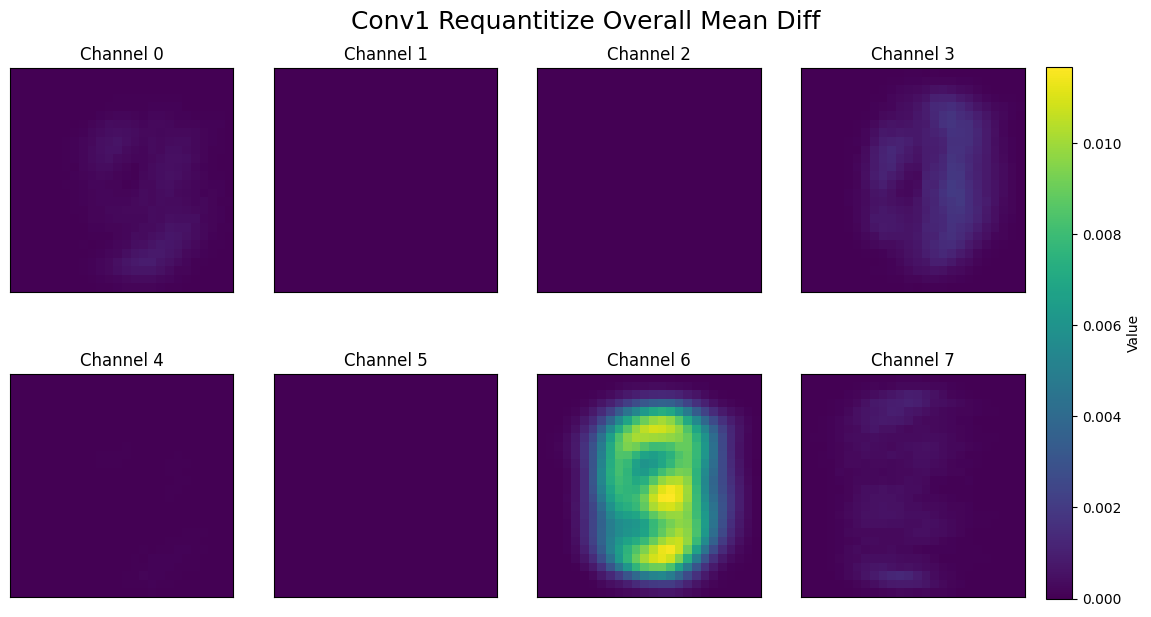

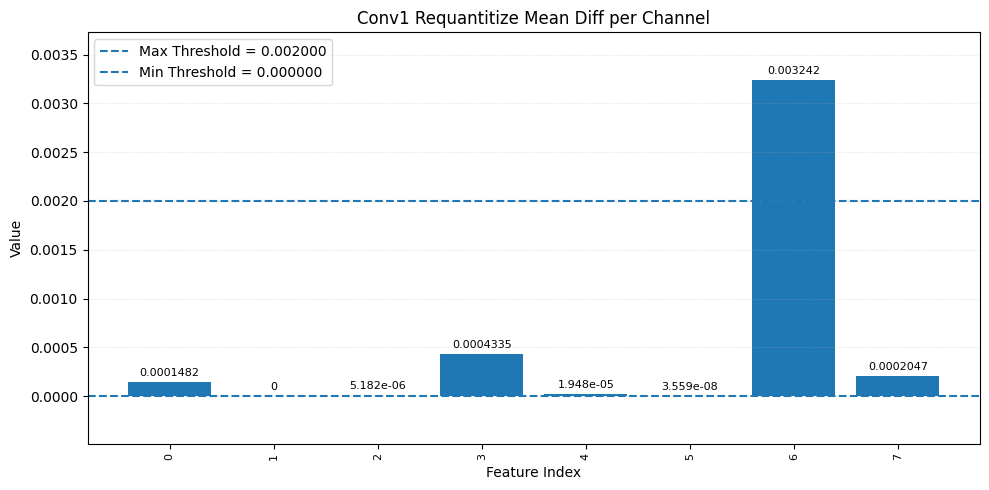

In [19]:
conv1_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/conv1_req.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(conv1_vivado_feature.shape)

conv1_req_vivado_ref = vivado_refrence_maker(
    conv1_vivado_feature, 
    total_pixel_num=676, 
    out_ch=8
)

print(len(conv1_req_vivado_ref), conv1_req_vivado_ref[0].shape)

top_mean_frames, top_pixel_frames, overall_mean = create_spatial_results_diff(
    conv1_python_feature.copy(),
    conv1_req_vivado_ref
)

print(top_mean_frames, overall_mean.shape)

create_subplot(
    overall_mean,
    title="Conv1 Requantitize Overall Mean Diff"
)

channel_mean = np.mean(
    overall_mean,
    axis=(1, 2)
)

plot_bar(
    channel_mean,
    title="Conv1 Requantitize Mean Diff per Channel",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True
)

In [20]:
# # overview the frame that has most high mean diff in produce conv1 feature

# for idx in top_mean_frames:
#     create_subplot(
#         conv1_req_vivado_ref[idx],
#         title=f"Frame-{idx} Conv1 Most High Different (Vivado Reff)",
#         folder_name="conv1_feature",
#         save=True,
#         show=False
#     )

#     create_subplot(
#         conv1_python_feature[idx],
#         title=f"Frame-{idx} Conv1 Most High Different (Python Reff)",
#         folder_name="conv1_feature",
#         save=True,
#         show=False
#     )

In [21]:
# for item in top_pixel_frames:
#     frame_idx = item['frame_idx']
#     channel_idx = item['channel_idx']
#     diff = item['diff']
#     channel_diff = item['channel_diff']
#     position = item['pixel_idx']
    
#     create_subplot(
#         conv1_req_vivado_ref[frame_idx],
#         title=f"Frame-{frame_idx} ch_{channel_idx}, position_{position}, pixel_diff_{diff:.2} ch_diff_{channel_diff:.2}",
#         folder_name="conv1_feature/outlier",
#         save=True,
#         show=False
#     )

(676000, 8)
(8,) (8,) (8,)


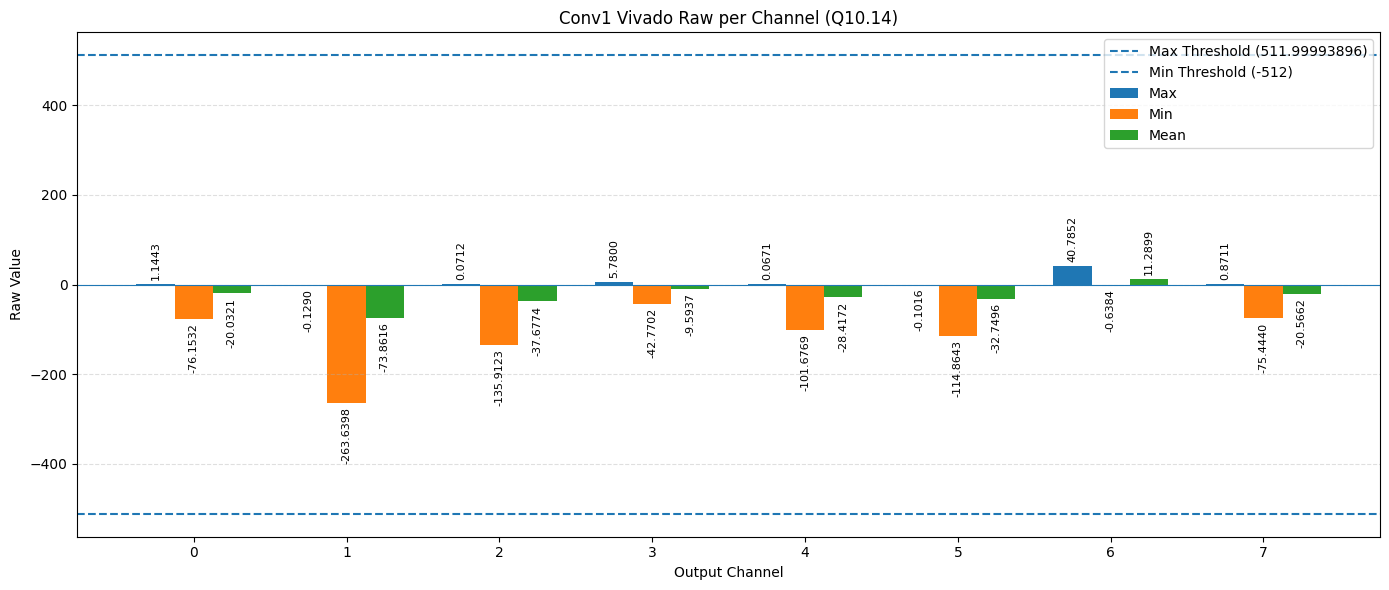

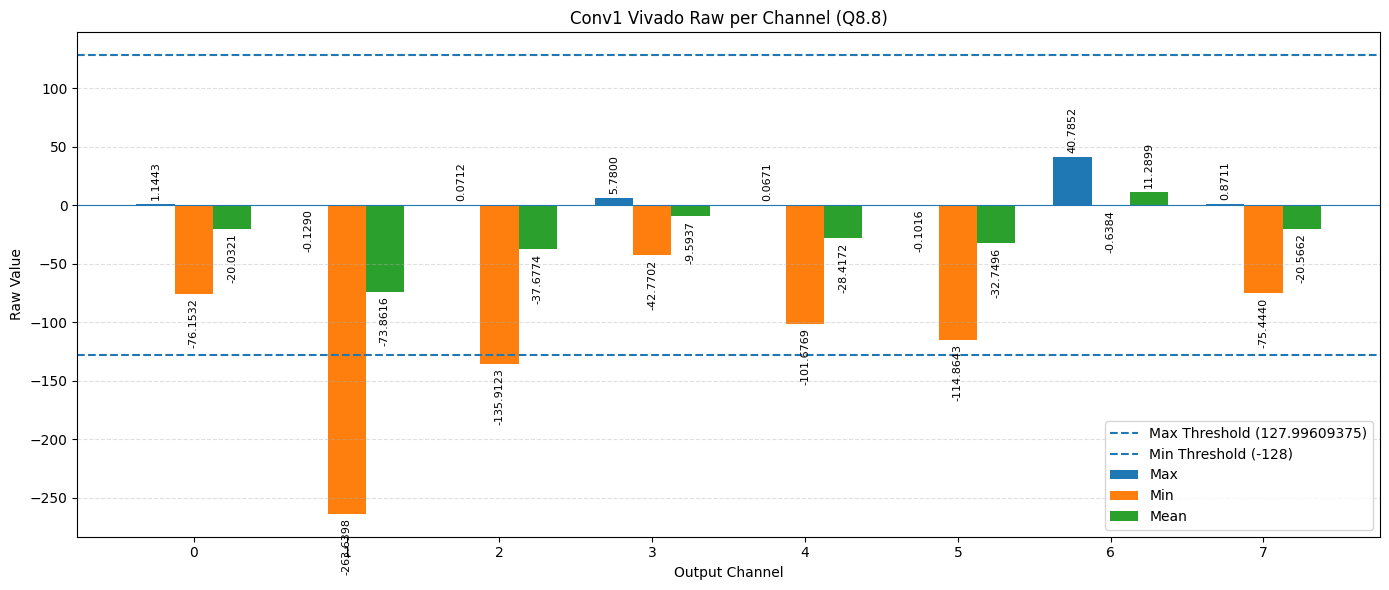

In [22]:
conv1_vivado_feature_raw = load_result_from_vivad_txt(
    "./sim-txt/conv1_raw.txt",
    row_bit=368,
    data_bit=46,
    fract_bit=28,
    total_bit=46
)

print(conv1_vivado_feature_raw.shape)

conv1_raw_vivado_ref = vivado_refrence_maker(
    conv1_vivado_feature_raw,
    total_pixel_num=676,
    out_ch=8
)

conv1_max, conv1_min, conv1_mean = create_treshold_spatial_data(conv1_raw_vivado_ref)

print(conv1_max.shape, conv1_min.shape, conv1_mean.shape)

plot_raw_treshold(
    conv1_max,
    conv1_min,
    conv1_mean,
    title="Conv1 Vivado Raw per Channel (Q10.14)",
    max_treshold=511.99993896,
    min_treshold=-512,
    xlabel="Output Channel",
    ylabel="Raw Value"
)

plot_raw_treshold(
    conv1_max,
    conv1_min,
    conv1_mean,
    title="Conv1 Vivado Raw per Channel (Q8.8)",
    max_treshold=127.99609375,
    min_treshold=-128,
    xlabel="Output Channel",
    ylabel="Raw Value"
)

## POOL1

1000 (8, 13, 13)
(169000, 8)
1000 (8, 13, 13)
[35, 875, 3, 25, 394, 316, 60, 84, 597, 218] (8, 13, 13)


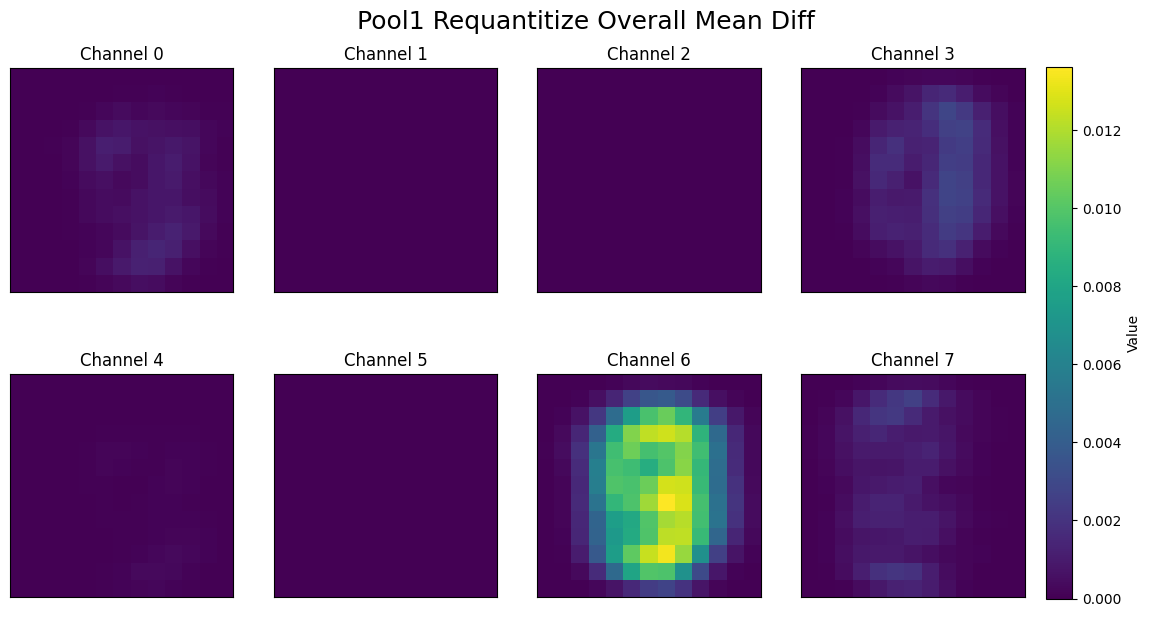

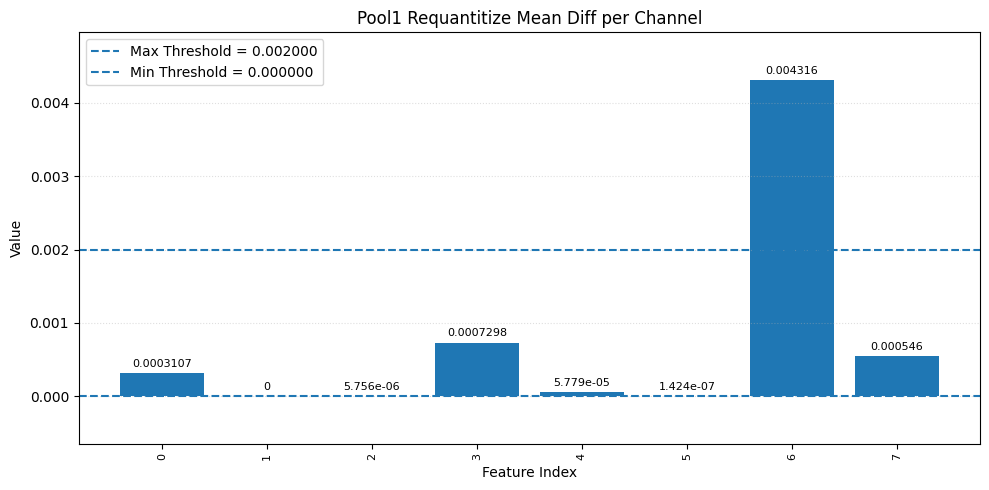

In [23]:
pool1_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    pool1_pred = model_pool1_predict(x)
    pool1_python_feature.append(pool1_pred)

print(len(pool1_python_feature), pool1_python_feature[0].shape)

pool1_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/pool1.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(pool1_vivado_feature.shape)

pool1_req_vivado_ref = vivado_refrence_maker(
    pool1_vivado_feature, 
    total_pixel_num=169, 
    out_ch=8
)

print(len(pool1_req_vivado_ref), pool1_req_vivado_ref[0].shape)

top_mean_frames, top_pixel_frames, overall_mean = create_spatial_results_diff(
    pool1_python_feature.copy(),
    pool1_req_vivado_ref
)

print(top_mean_frames, overall_mean.shape)

create_subplot(
    overall_mean,
    title="Pool1 Requantitize Overall Mean Diff"
)

channel_mean = np.mean(
    overall_mean,
    axis=(1, 2)
)

plot_bar(
    channel_mean,
    title="Pool1 Requantitize Mean Diff per Channel",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True
)

## CONV2

In [24]:
conv2_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    conv2_pred = model_conv2_predict(x)
    conv2_python_feature.append(conv2_pred)

print(len(conv2_python_feature), conv2_python_feature[0].shape)

1000 (16, 11, 11)


(242000, 8)
1000 (16, 11, 11)
[25, 35, 875, 3, 394, 316, 218, 396, 337, 365] (16, 11, 11)


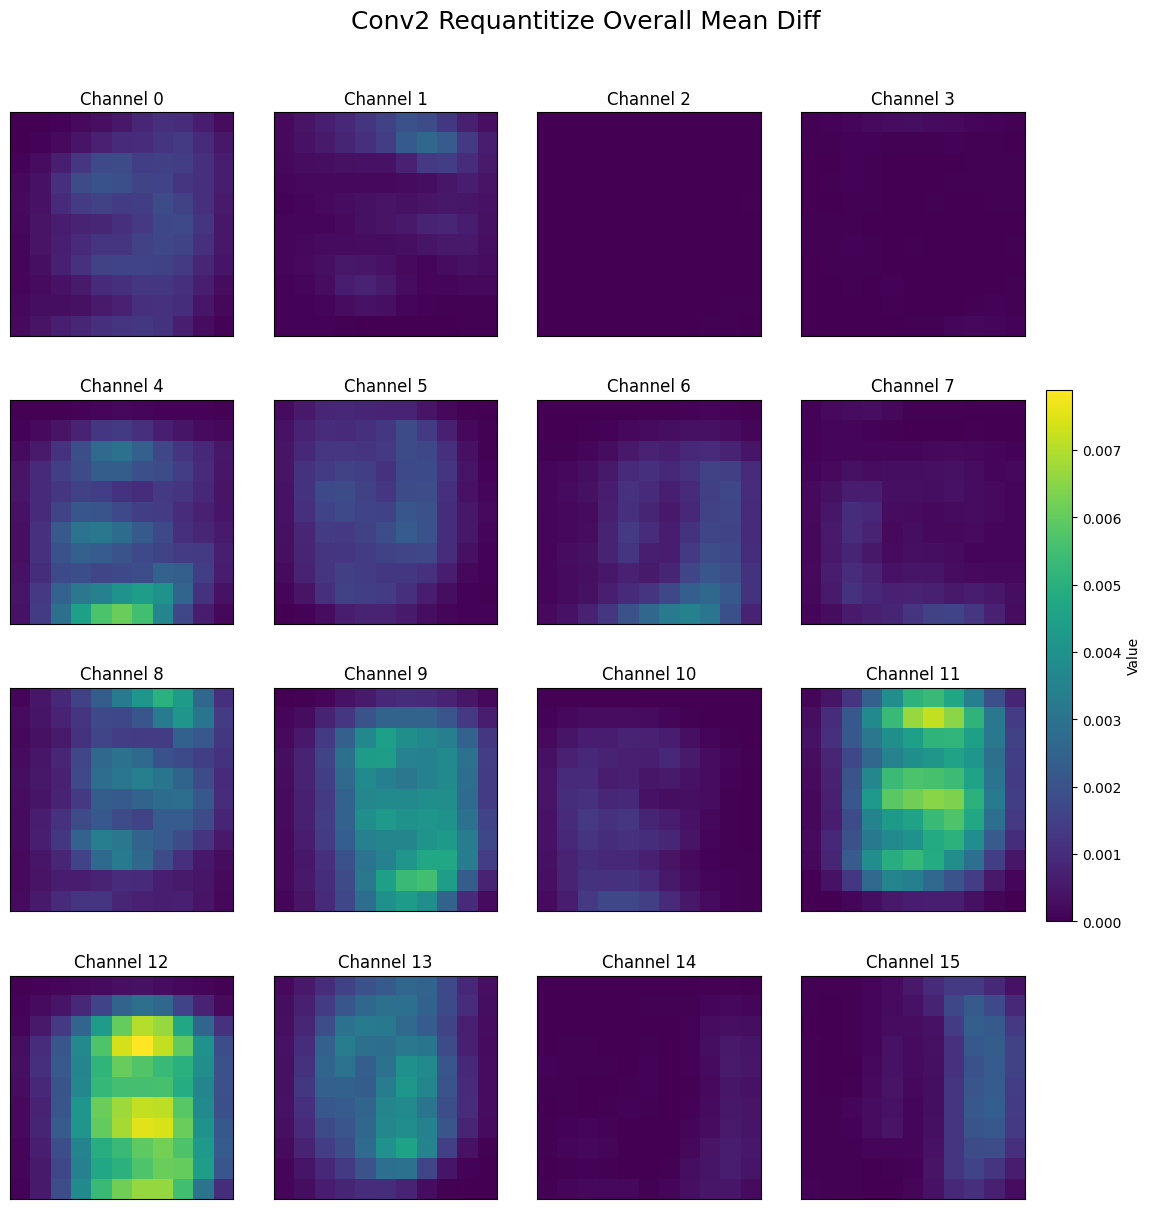

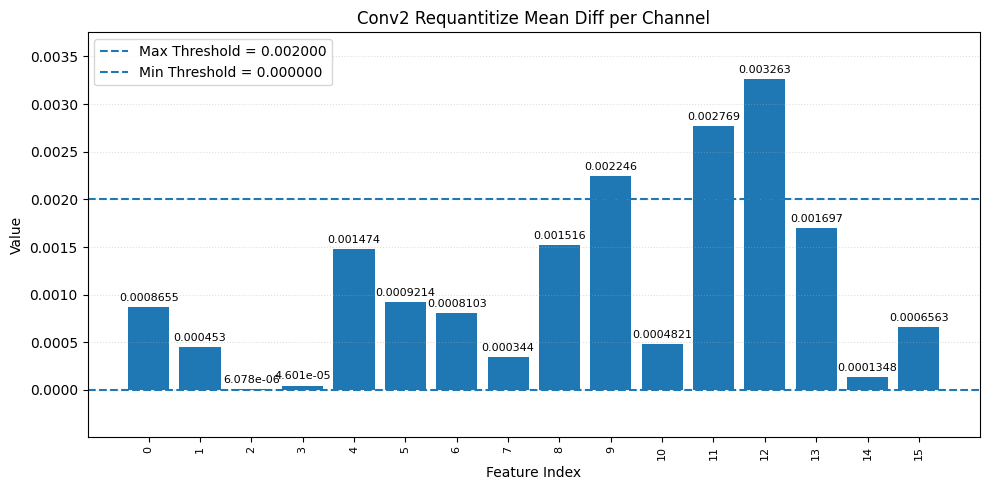

In [25]:
conv2_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/conv2_req.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(conv2_vivado_feature.shape)

conv2_req_vivado_ref = vivado_refrence_maker(
    conv2_vivado_feature,
    total_pixel_num=121,
    out_ch=16
)

print(len(conv2_req_vivado_ref), conv2_req_vivado_ref[0].shape)

top_mean_frames, top_pixel_frames, overall_mean = create_spatial_results_diff(
    conv2_python_feature.copy(),
    conv2_req_vivado_ref
)

print(top_mean_frames, overall_mean.shape)

create_subplot(
    overall_mean,
    title="Conv2 Requantitize Overall Mean Diff"
)

channel_mean = np.mean(
    overall_mean,
    axis=(1, 2)
)

plot_bar(
    channel_mean,
    title="Conv2 Requantitize Mean Diff per Channel",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True
)


In [26]:
# # overview the frame that has most high mean diff in produce conv2 feature

# for idx in top_mean_frames:
#     create_subplot(
#         conv2_req_vivado_ref[idx],
#         title=f"Frame-{idx} Conv2 Most High Different (Vivado Reff)",
#         folder_name="conv2_feature",
#         save=True,
#         show=False
#     )

#     create_subplot(
#         conv2_python_feature[idx],
#         title=f"Frame-{idx} Conv2 Most High Different (Python Reff)",
#         folder_name="conv2_feature",
#         save=True,
#         show=False
#     )

In [27]:
# for item in top_pixel_frames:
#     frame_idx = item['frame_idx']
#     channel_idx = item['channel_idx']
#     diff = item['diff']
#     channel_diff = item['channel_diff']
#     position = item['pixel_idx']
    
#     create_subplot(
#         conv2_req_vivado_ref[frame_idx],
#         title=f"Frame-{frame_idx} ch_{channel_idx}, position_{position}, pixel_diff_{diff:.2} ch_diff_{channel_diff:.2}",
#         folder_name="conv2_feature/outlier",
#         save=True,
#         show=False
#     )

(242000, 8)
1000 (16, 11, 11)
(16,) (16,) (16,)


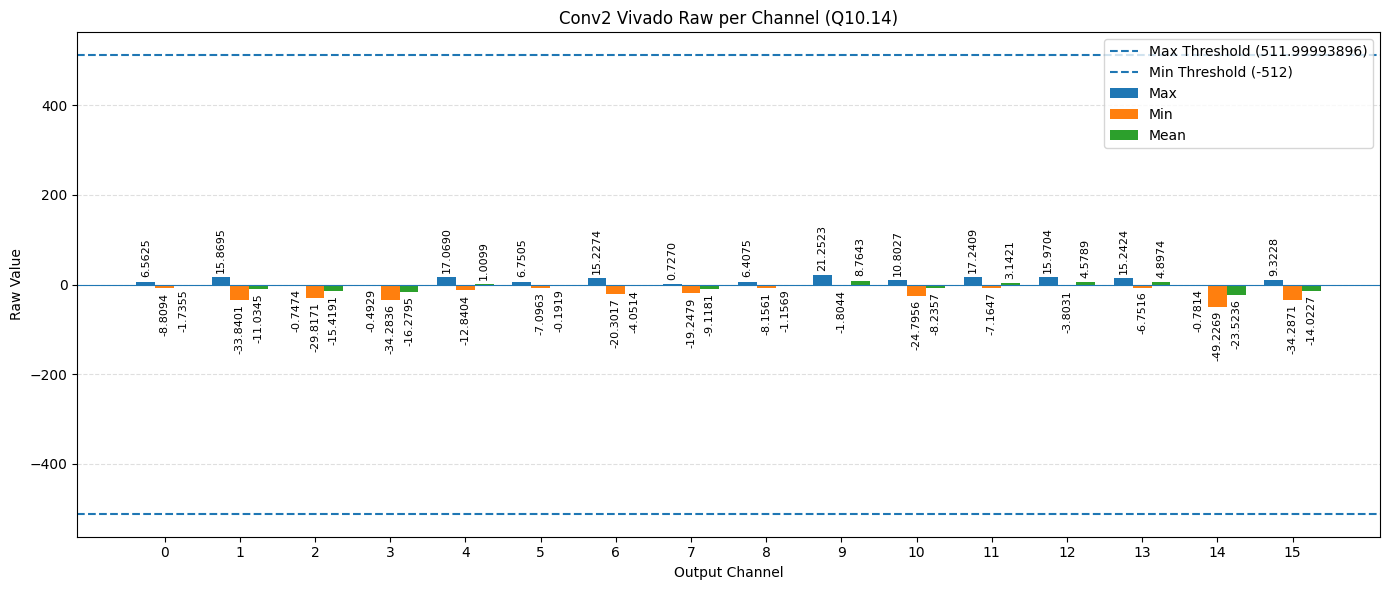

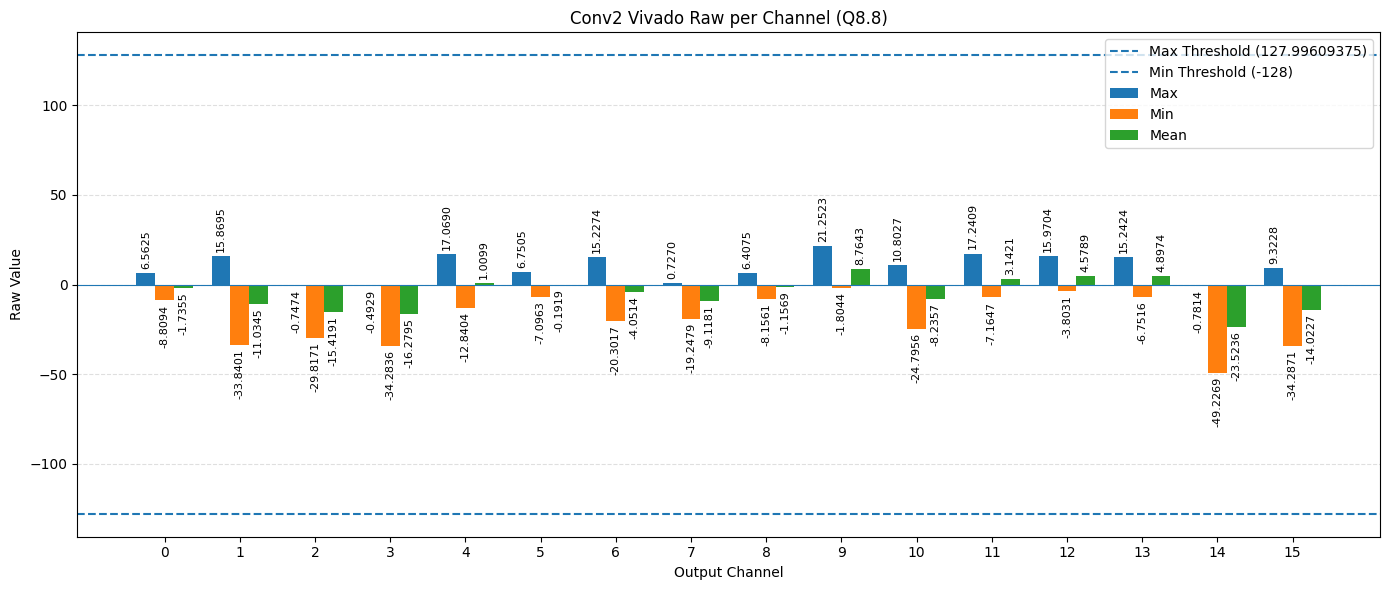

In [28]:
conv2_vivado_feature_raw = load_result_from_vivad_txt(
    "./sim-txt/conv2_raw.txt",
    row_bit=392,
    data_bit=49,
    fract_bit=28,
    total_bit=49
)

print(conv2_vivado_feature_raw.shape)

conv2_raw_vivado_ref = vivado_refrence_maker(
    conv2_vivado_feature_raw, 
    total_pixel_num=121, 
    out_ch=16
)

print(len(conv2_raw_vivado_ref), conv2_raw_vivado_ref[0].shape)

conv2_max, conv2_min, conv2_mean = create_treshold_spatial_data(conv2_raw_vivado_ref)

print(conv2_max.shape, conv2_min.shape, conv2_mean.shape)

plot_raw_treshold(
    conv2_max,
    conv2_min,
    conv2_mean,
    title="Conv2 Vivado Raw per Channel (Q10.14)",
    max_treshold=511.99993896,
    min_treshold=-512,
    xlabel="Output Channel",
    ylabel="Raw Value"
)

plot_raw_treshold(
    conv2_max,
    conv2_min,
    conv2_mean,
    title="Conv2 Vivado Raw per Channel (Q8.8)",
    max_treshold=127.99609375,
    min_treshold=-128,
    xlabel="Output Channel",
    ylabel="Raw Value"
)

## POOL2

In [29]:
pool2_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    pool2_pred = model_pool2_predict(x)
    pool2_python_feature.append(pool2_pred)

print(len(pool2_python_feature), pool2_python_feature[0].shape)

1000 (16, 5, 5)


(50000, 8)
1000 (16, 5, 5)
[877, 25, 35, 875, 218, 285, 627, 339, 3, 879] (16, 5, 5)


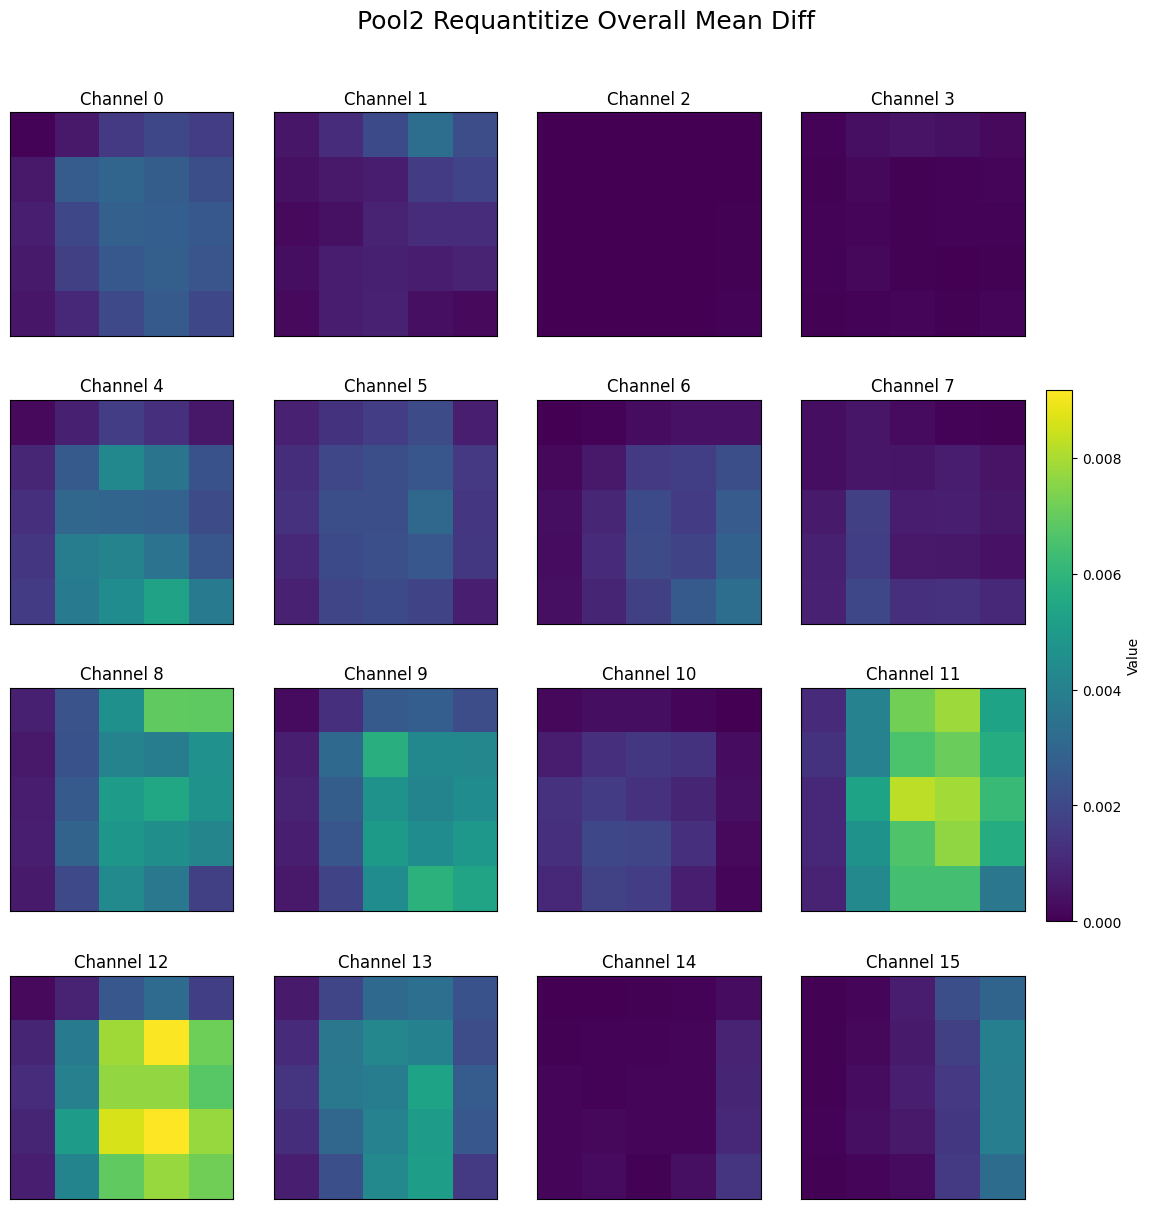

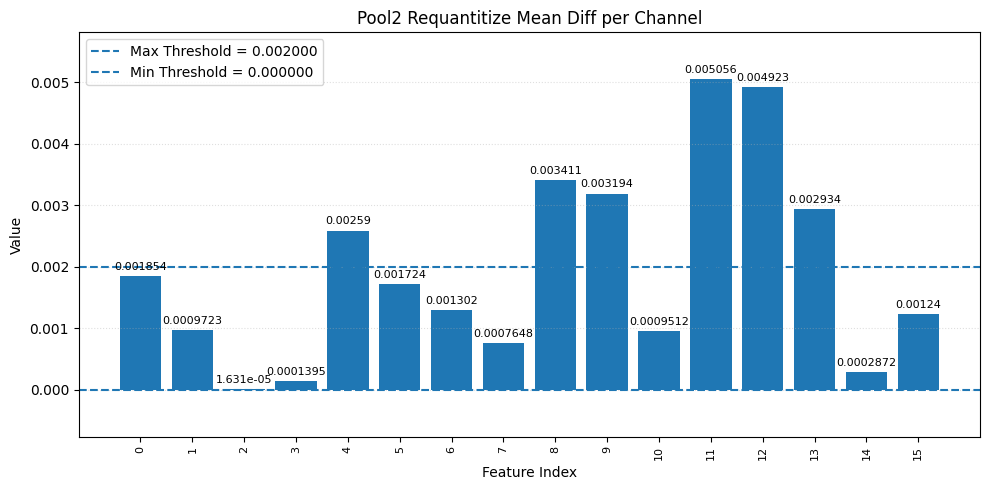

In [30]:
pool2_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/pool2.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(pool2_vivado_feature.shape)

pool2_req_vivado_ref = vivado_refrence_maker(
    pool2_vivado_feature, 
    total_pixel_num=25, 
    out_ch=16
)

print(len(pool2_req_vivado_ref), pool2_req_vivado_ref[0].shape)

top_mean_frames, top_pixel_frames, overall_mean = create_spatial_results_diff(
    pool2_python_feature.copy(),
    pool2_req_vivado_ref
)

print(top_mean_frames, overall_mean.shape)

create_subplot(
    overall_mean,
    title="Pool2 Requantitize Overall Mean Diff"
)

channel_mean = np.mean(
    overall_mean,
    axis=(1, 2)
)

plot_bar(
    channel_mean,
    title="Pool2 Requantitize Mean Diff per Channel",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True
)

## CONV3

In [31]:
conv3_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    conv3_pred = model_conv3_predict(x)
    conv3_python_feature.append(conv3_pred)

print(len(conv3_python_feature), conv3_python_feature[0].shape)

1000 (32, 3, 3)


(36000, 8)
1000 (32, 3, 3)
[875, 35, 877, 627, 218, 25, 888, 898, 3, 841] (32, 3, 3)


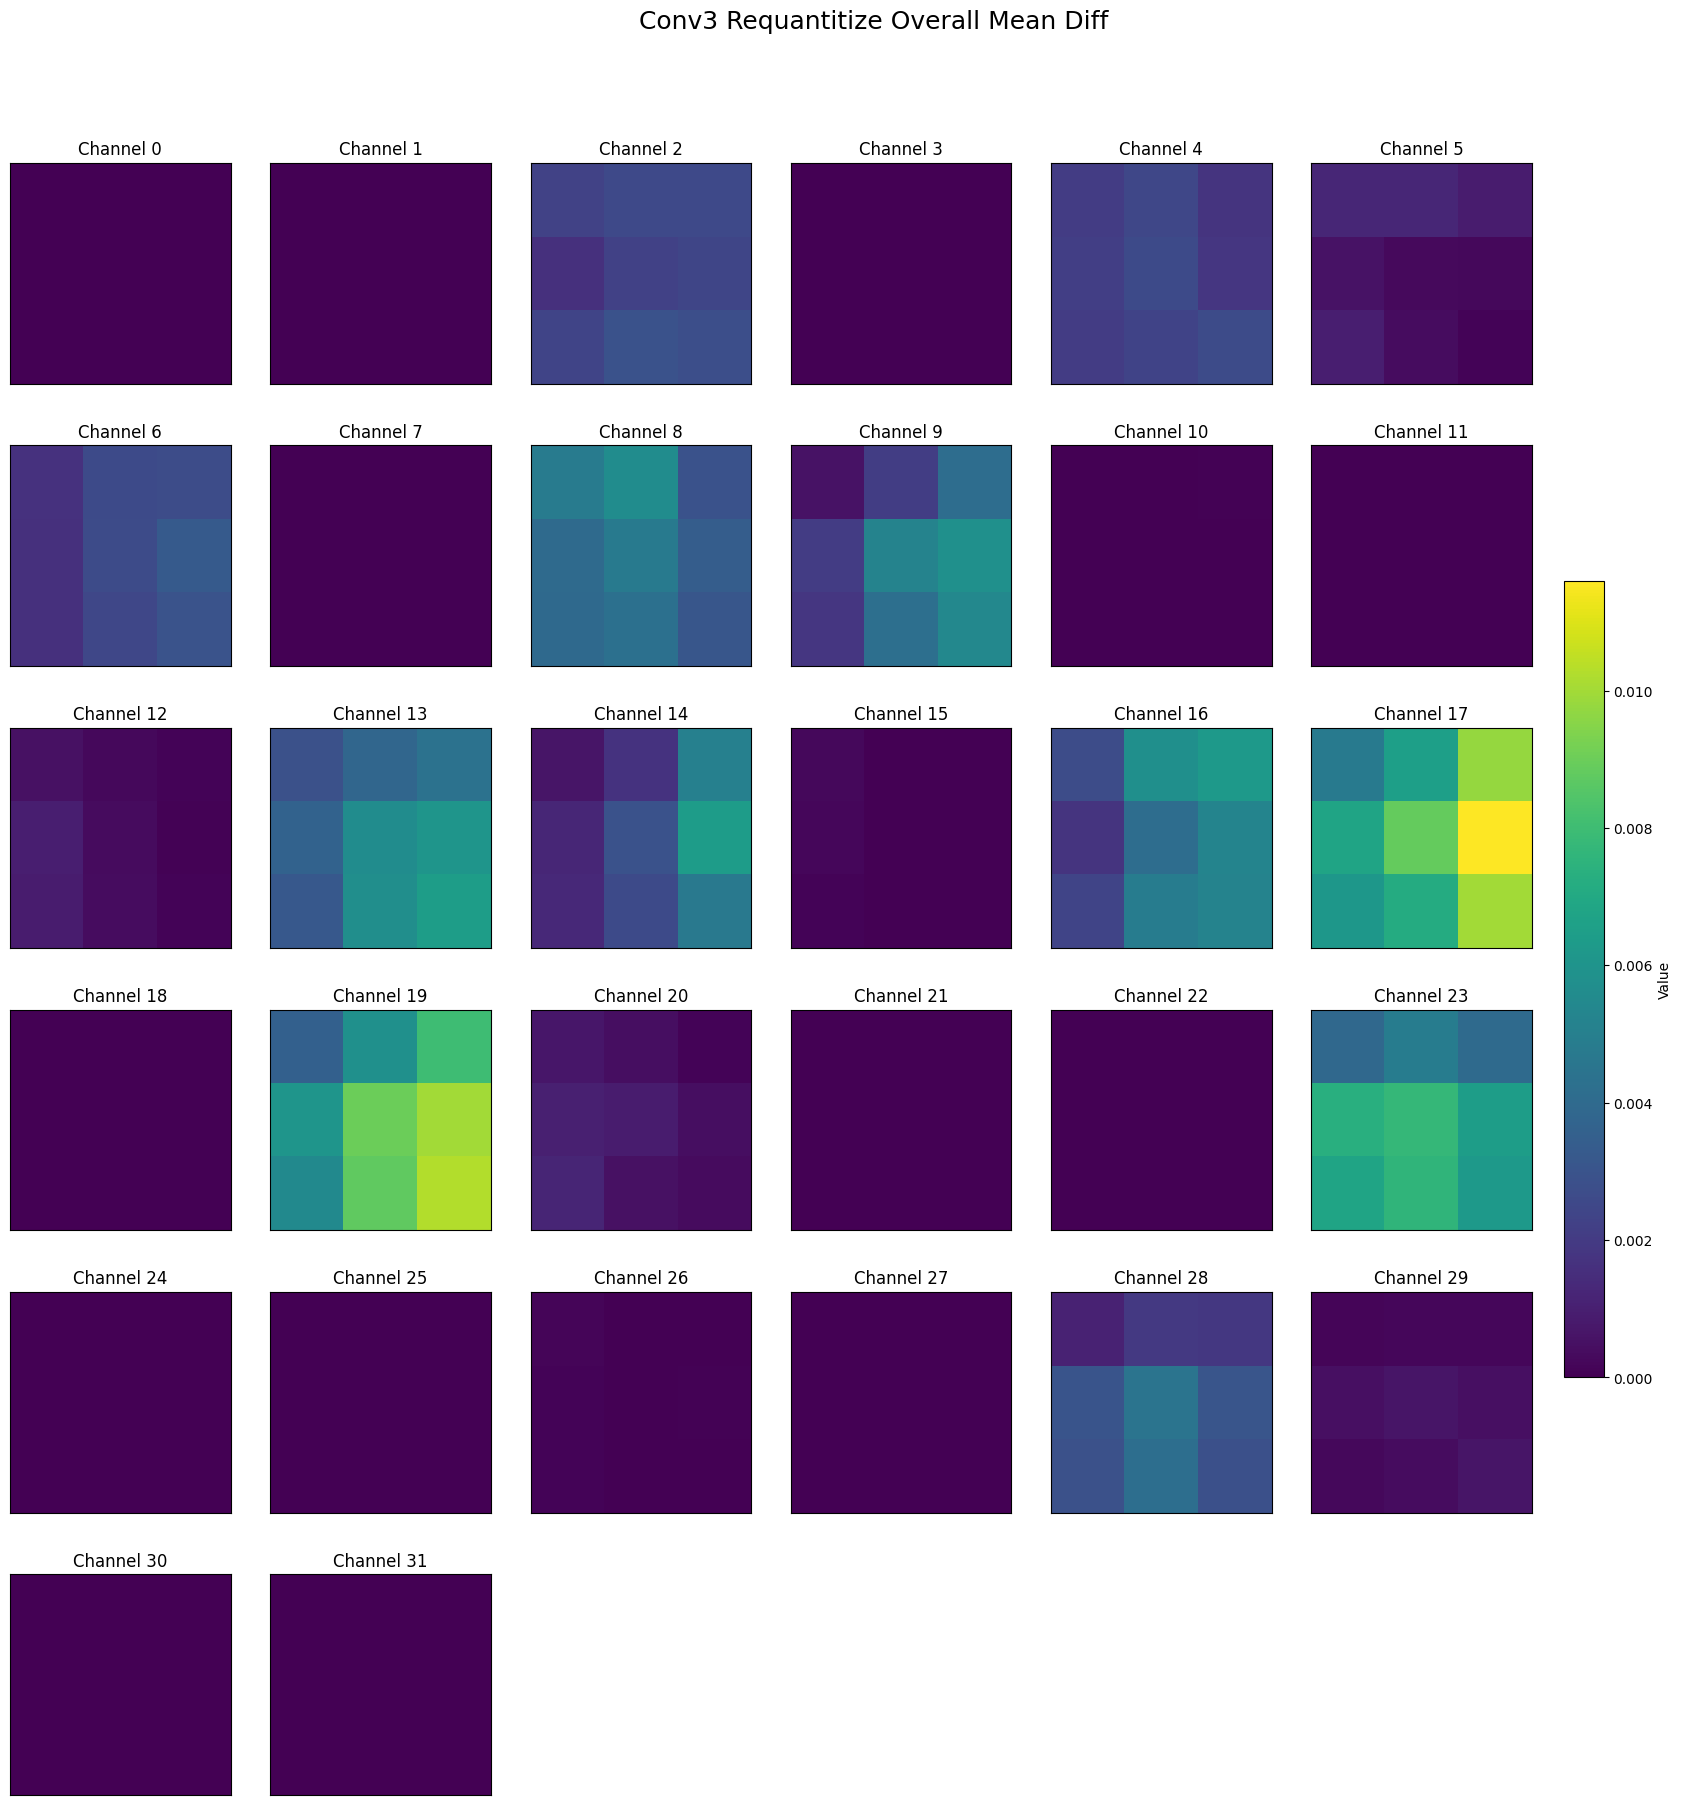

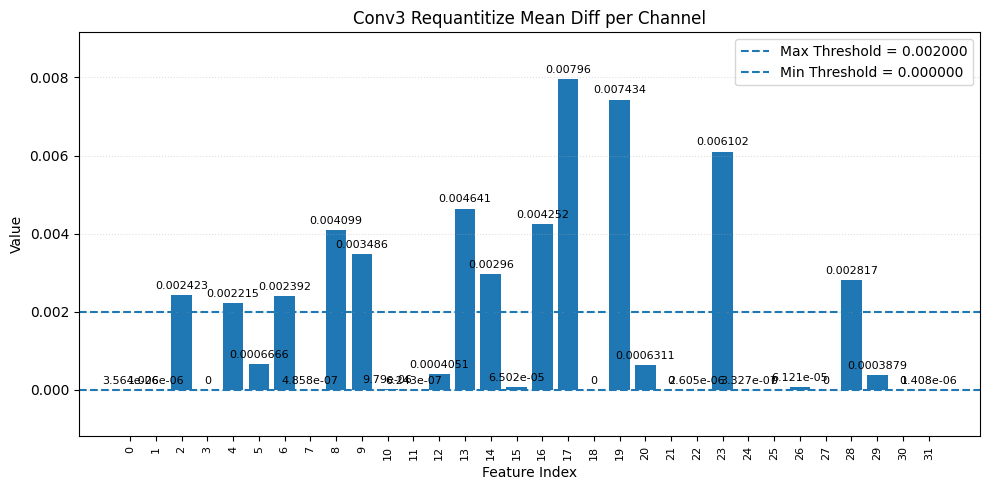

In [32]:
conv3_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/conv3_req.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(conv3_vivado_feature.shape)

conv3_req_vivado_ref = vivado_refrence_maker(
    conv3_vivado_feature, 
    total_pixel_num=9, 
    out_ch=32
)

print(len(conv3_req_vivado_ref), conv3_req_vivado_ref[0].shape)

top_mean_frames, top_pixel_frames, overall_mean = create_spatial_results_diff(
    conv3_python_feature.copy(),
    conv3_req_vivado_ref
)

print(top_mean_frames, overall_mean.shape)

create_subplot(
    overall_mean,
    title="Conv3 Requantitize Overall Mean Diff"
)

channel_mean = np.mean(
    overall_mean,
    axis=(1, 2)
)

plot_bar(
    channel_mean,
    title="Conv3 Requantitize Mean Diff per Channel",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True
)

In [33]:
# # overview the frame that has most high mean diff in produce conv3 feature

# for idx in top_mean_frames:
#     create_subplot(
#         conv3_req_vivado_ref[idx],
#         title=f"Frame-{idx} Conv3 Most High Different (Vivado Reff)",
#         folder_name="conv3_feature",
#         save=True,
#         show=False
#     )

#     create_subplot(
#         conv3_python_feature[idx],
#         title=f"Frame-{idx} Conv3 Most High Different (Python Reff)",
#         folder_name="conv3_feature",
#         save=True,
#         show=False
#     )

In [34]:
# for item in top_pixel_frames:
#     frame_idx = item['frame_idx']
#     channel_idx = item['channel_idx']
#     diff = item['diff']
#     channel_diff = item['channel_diff']
#     position = item['pixel_idx']
    
#     create_subplot(
#         conv3_req_vivado_ref[frame_idx],
#         title=f"Frame-{frame_idx} ch_{channel_idx}, position_{position}, pixel_diff_{diff:.2} ch_diff_{channel_diff:.2}",
#         folder_name="conv3_feature/outlier",
#         save=True,
#         show=False
#     )

(36000, 8)
1000 (32, 3, 3)
(32,) (32,) (32,)


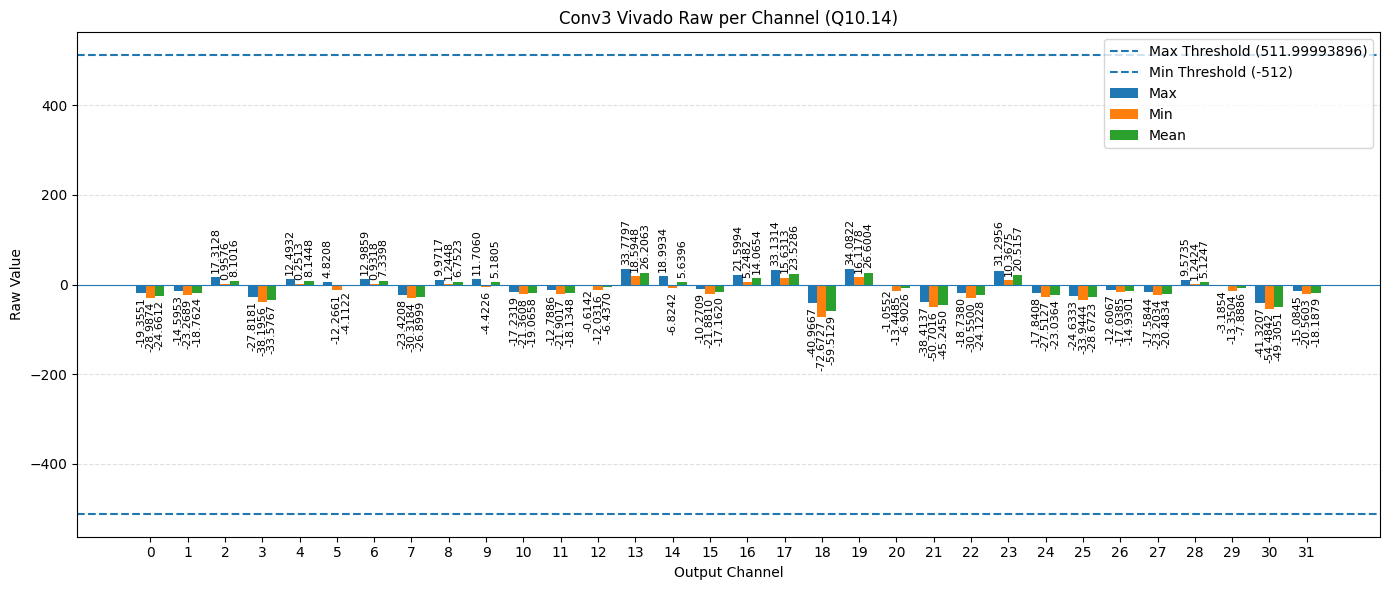

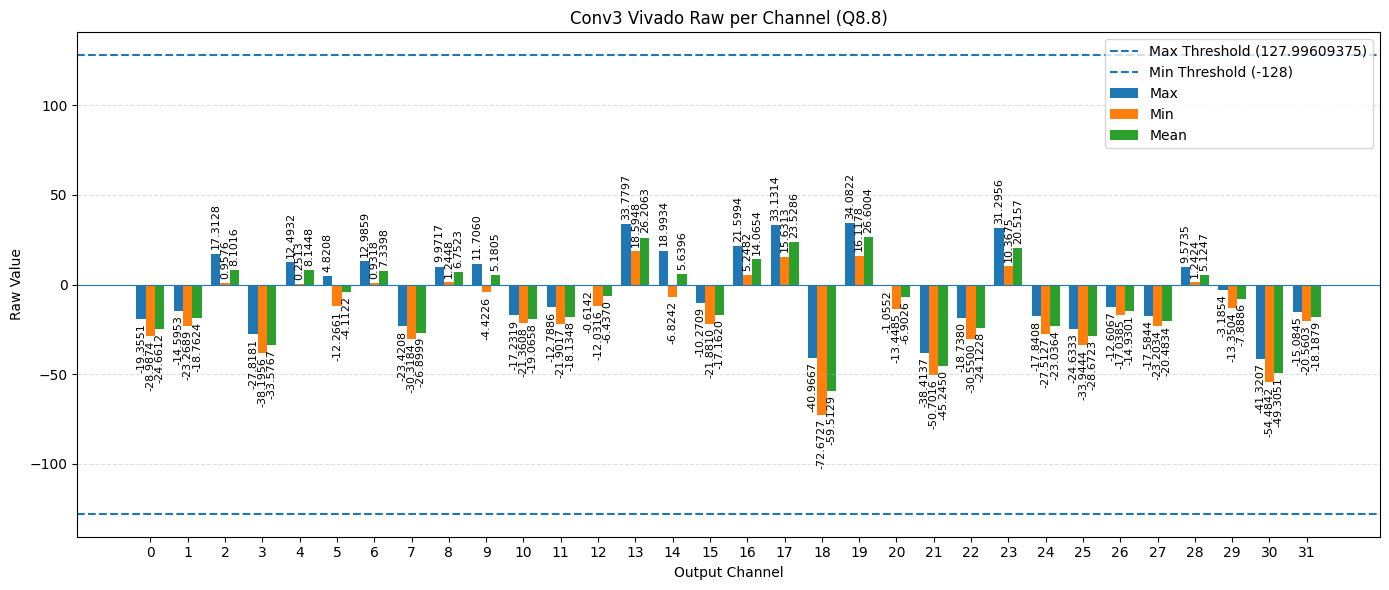

In [35]:
conv3_vivado_feature_raw = load_result_from_vivad_txt(
    "./sim-txt/conv3_raw.txt",
    row_bit=400,
    data_bit=50,
    fract_bit=28,
    total_bit=50
)

print(conv3_vivado_feature_raw.shape)

conv3_raw_vivado_ref = vivado_refrence_maker(
    conv3_vivado_feature_raw, 
    total_pixel_num=9, 
    out_ch=32
)

print(len(conv3_raw_vivado_ref), conv3_raw_vivado_ref[0].shape)

conv3_max, conv3_min, conv3_mean = create_treshold_spatial_data(conv3_raw_vivado_ref)

print(conv3_max.shape, conv3_min.shape, conv3_mean.shape)

plot_raw_treshold(
    conv3_max,
    conv3_min,
    conv3_mean,
    title="Conv3 Vivado Raw per Channel (Q10.14)",
    max_treshold=511.99993896,
    min_treshold=-512,
    xlabel="Output Channel",
    ylabel="Raw Value"
)

plot_raw_treshold(
    conv3_max,
    conv3_min,
    conv3_mean,
    title="Conv3 Vivado Raw per Channel (Q8.8)",
    max_treshold=127.99609375,
    min_treshold=-128,
    xlabel="Output Channel",
    ylabel="Raw Value"
)

## POOL3

In [36]:
pool3_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    pool3_pred = model_pool3_predict(x)
    pool3_python_feature.append(pool3_pred)

print(len(pool3_python_feature), pool3_python_feature[0].shape)

1000 (32, 1, 1)


(4000, 8)
1000 (32, 1, 1)
[875, 884, 898, 592, 25, 285, 877, 879, 817, 79] (32, 1, 1)


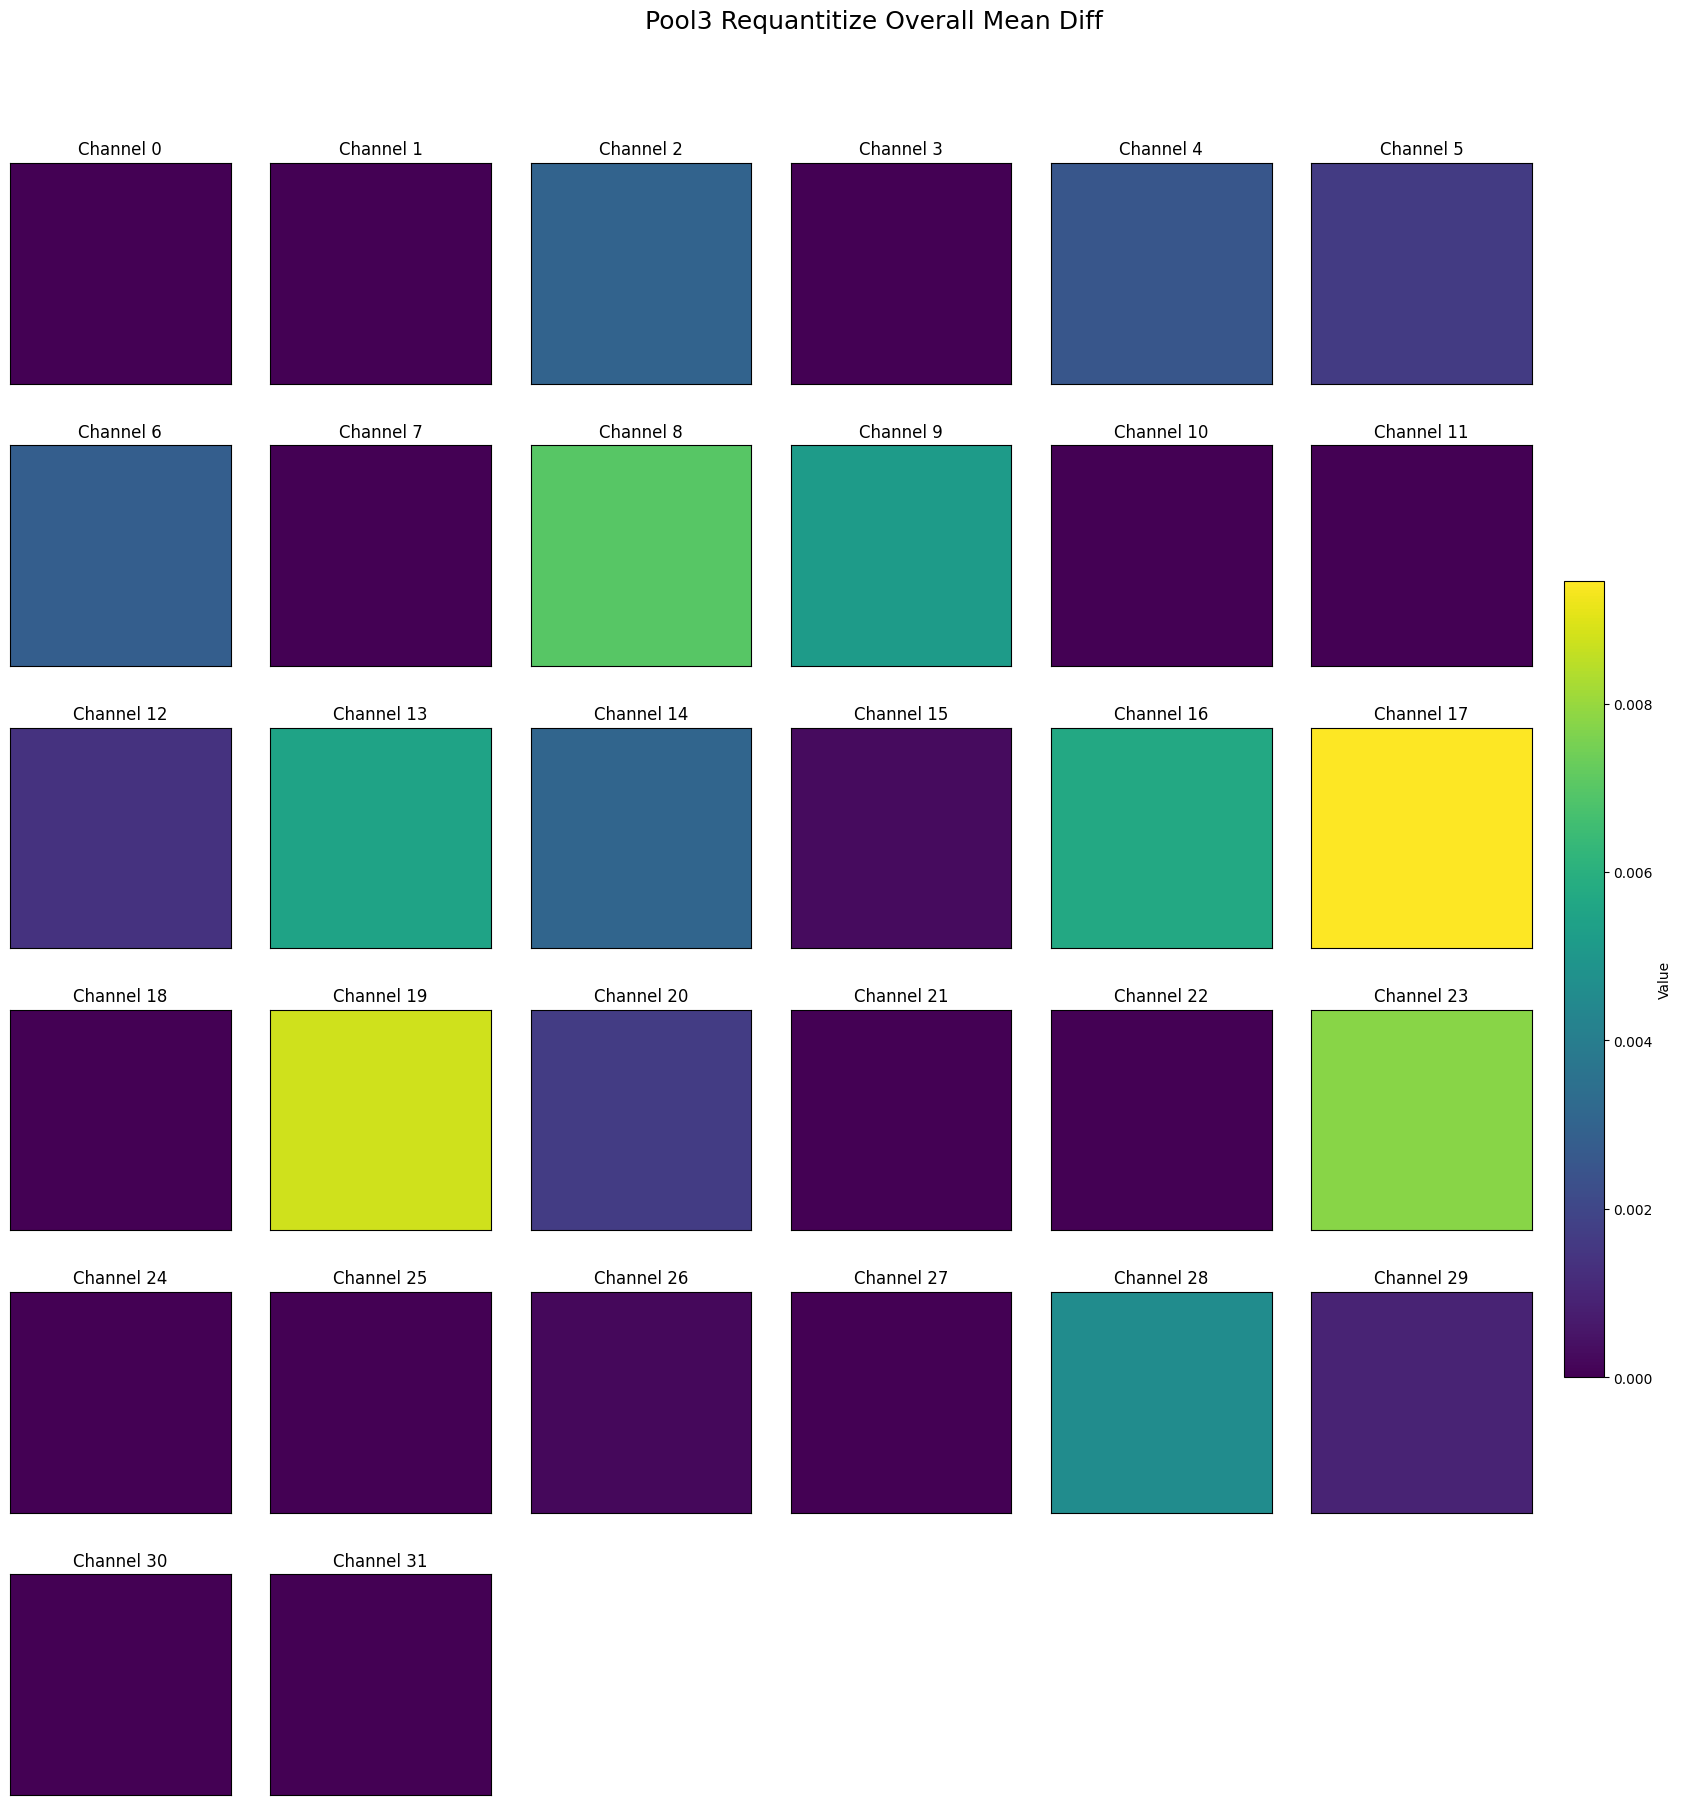

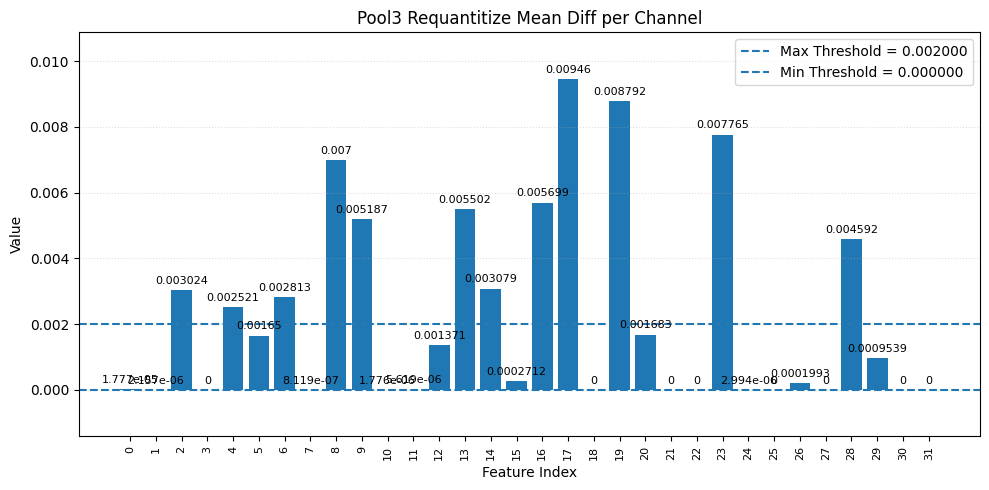

In [37]:
pool3_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/pool3.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(pool3_vivado_feature.shape)

pool3_req_vivado_ref = vivado_refrence_maker(
    pool3_vivado_feature, 
    total_pixel_num=1, 
    out_ch=32
)

print(len(pool3_req_vivado_ref), pool3_req_vivado_ref[0].shape)

top_mean_frames, top_pixel_frames, overall_mean = create_spatial_results_diff(
    pool3_python_feature.copy(),
    pool3_req_vivado_ref
)

print(top_mean_frames, overall_mean.shape)

create_subplot(
    overall_mean,
    title="Pool3 Requantitize Overall Mean Diff"
)

channel_mean = np.mean(
    overall_mean,
    axis=(1, 2)
)

plot_bar(
    channel_mean,
    title="Pool3 Requantitize Mean Diff per Channel",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True
)

## FC1

In [38]:
fc1_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    fc1_pred = model_fc1_predict(x)
    fc1_python_feature.append(fc1_pred)

print(len(fc1_python_feature), fc1_python_feature[0].shape)

1000 (1, 16)


(2000, 8)
1000 (16, 1, 1)
(1000,) (1000, 16)


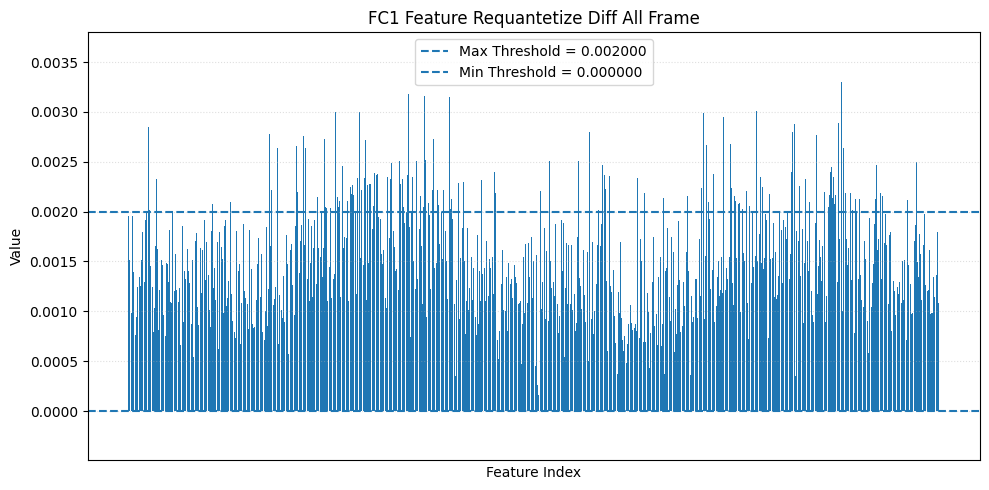

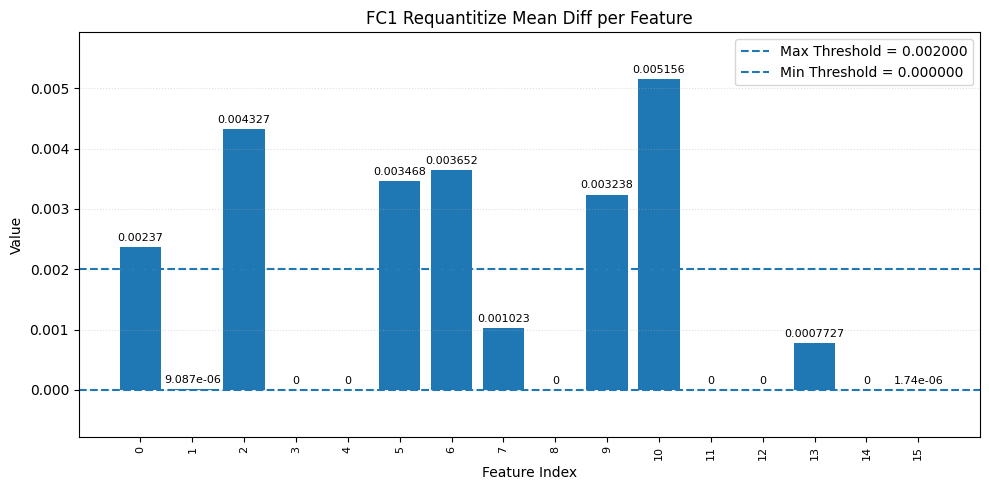

In [39]:
fc1_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/fc1_req.txt",
    row_bit=192,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(fc1_vivado_feature.shape)

fc1_req_vivado_ref = vivado_refrence_maker(
    fc1_vivado_feature, 
    total_pixel_num=1,
    out_ch=16,
    ch_in_row=8
)

print(len(fc1_req_vivado_ref), fc1_req_vivado_ref[0].shape)

fc1_mean_per_frame, fc1_mean_with_feature = calculate_vector_data(
    fc1_python_feature,
    fc1_req_vivado_ref
)

print(fc1_mean_per_frame.shape, fc1_mean_with_feature.shape)

plot_bar(
    fc1_mean_per_frame,
    title=f"FC1 Feature Requantetize Diff All Frame",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=False,
    show_value=False
)

fc1_mean_with_feature_mean = np.mean(
    fc1_mean_with_feature,
    axis=0
)

plot_bar(
    fc1_mean_with_feature_mean,
    title="FC1 Requantitize Mean Diff per Feature",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True,
    show_value=True
)

(2000, 8)
1000 (16, 1, 1)
(16,) (16,) (16,)


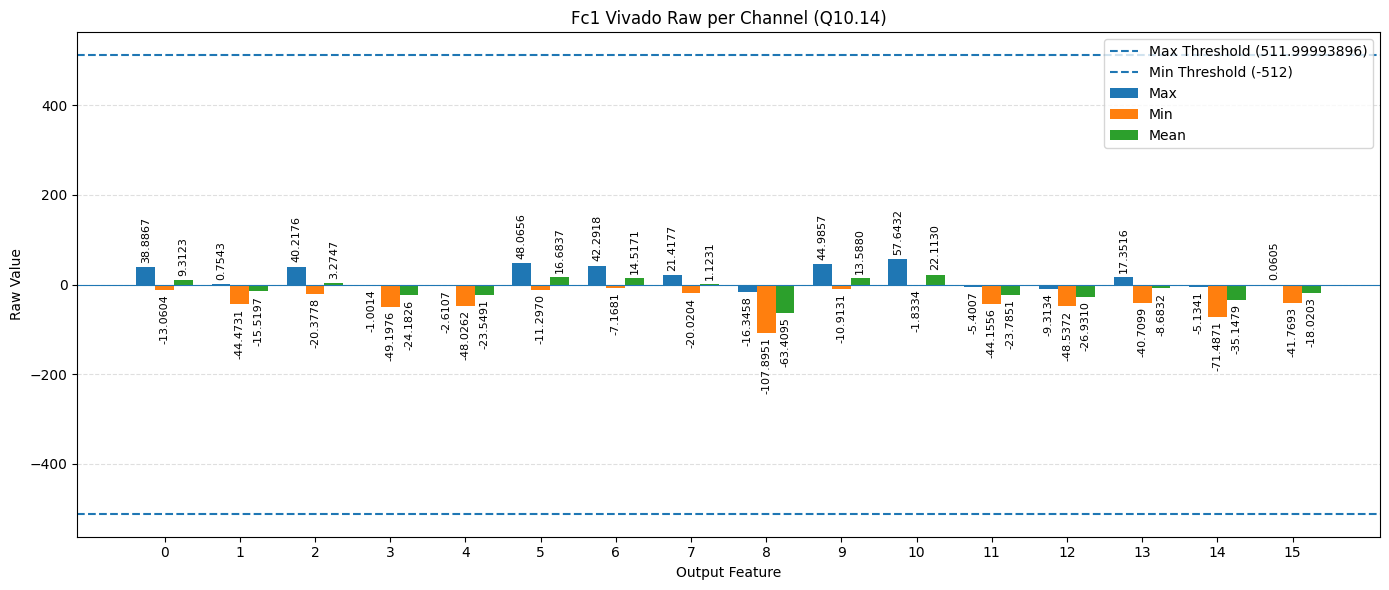

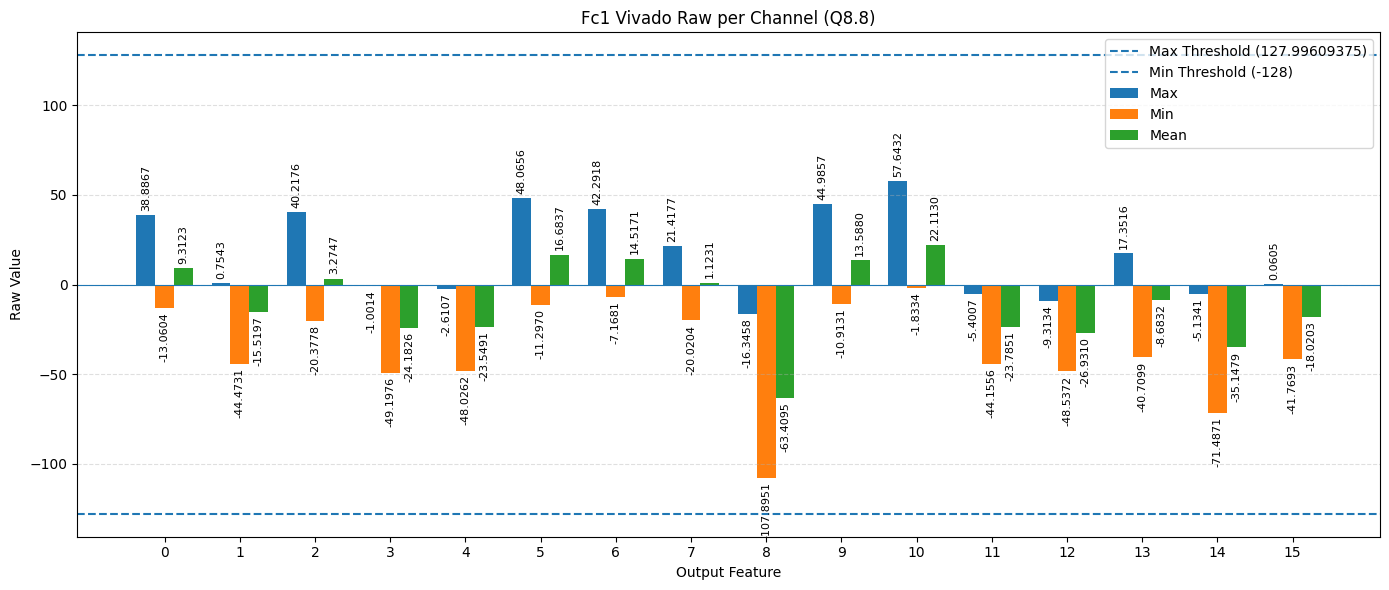

In [40]:
fc1_vivado_feature_raw = load_result_from_vivad_txt(
    "./sim-txt/fc1_raw.txt",
    row_bit=368,
    data_bit=46,
    fract_bit=28,
    total_bit=46
)

print(fc1_vivado_feature_raw.shape)

fc1_raw_vivado_ref = vivado_refrence_maker(
    fc1_vivado_feature_raw, 
    total_pixel_num=1,
    out_ch=16,
    ch_in_row=8
)

print(len(fc1_raw_vivado_ref), fc1_raw_vivado_ref[0].shape)

fc1_max, fc1_min, fc1_mean = create_treshold_vector_data(fc1_raw_vivado_ref)

print(fc1_max.shape, fc1_min.shape, fc1_mean.shape)

plot_raw_treshold(
    fc1_max,
    fc1_min,
    fc1_mean,
    title="Fc1 Vivado Raw per Channel (Q10.14)",
    max_treshold=511.99993896,
    min_treshold=-512,
    xlabel="Output Feature",
    ylabel="Raw Value"
)

plot_raw_treshold(
    fc1_max,
    fc1_min,
    fc1_mean,
    title="Fc1 Vivado Raw per Channel (Q8.8)",
    max_treshold=127.99609375,
    min_treshold=-128,
    xlabel="Output Feature",
    ylabel="Raw Value"
)

## FC2

In [41]:
fc2_python_feature = []

for i in range(1000):
    x = x_all_data[i]
    fc2_pred = model_fc2_predict(x)
    fc2_python_feature.append(fc2_pred)

print(len(fc2_python_feature), fc2_python_feature[0].shape)

1000 (1, 10)


(1000, 10)
1000 (10, 1, 1)
(1000,) (1000,)


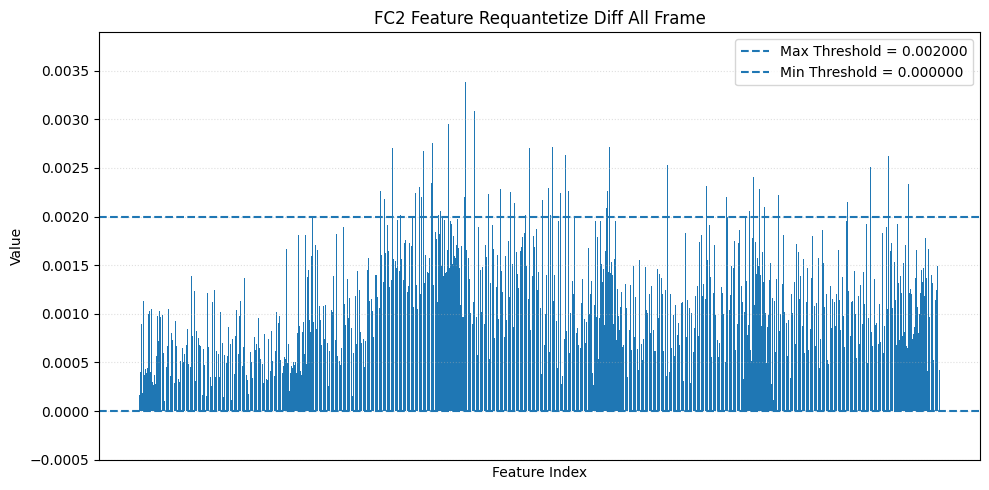

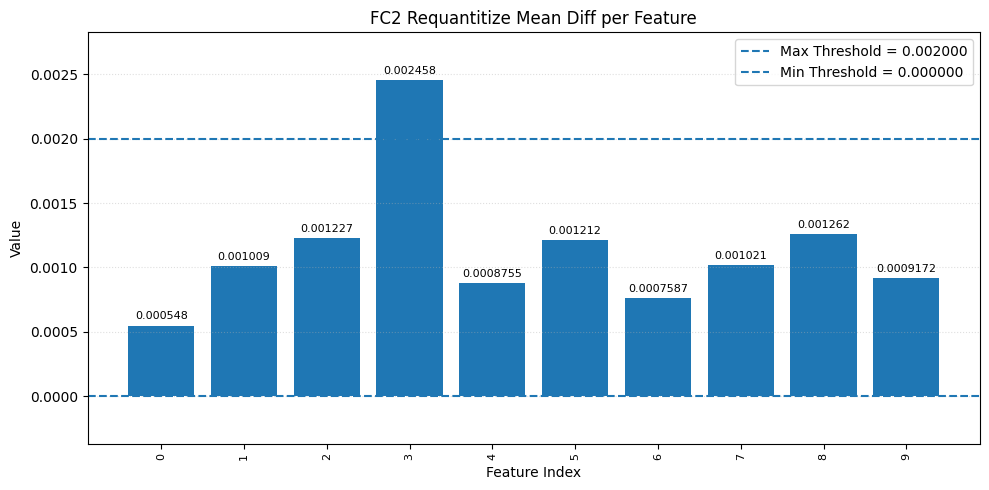

In [42]:
fc2_vivado_feature = load_result_from_vivad_txt(
    "./sim-txt/fc2_req.txt",
    row_bit=240,
    data_bit=24,
    fract_bit=14,
    total_bit=24
)

print(fc2_vivado_feature.shape)

fc2_req_vivado_ref = vivado_refrence_maker(
    fc2_vivado_feature, 
    total_pixel_num=1,
    out_ch=10,
    ch_in_row=10
)

print(len(fc2_req_vivado_ref), fc2_req_vivado_ref[0].shape)

fc2_mean_per_frame, fc2_mean_with_feature = calculate_vector_data(
    fc2_python_feature,
    fc2_req_vivado_ref
)

print(fc2_mean_per_frame.shape, fc2_mean_per_frame.shape)

plot_bar(
    fc2_mean_per_frame,
    title=f"FC2 Feature Requantetize Diff All Frame",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=False,
    show_value=False
)

fc2_mean_with_feature_mean = np.mean(
    fc2_mean_with_feature,
    axis=0
)

plot_bar(
    fc2_mean_with_feature_mean,
    title="FC2 Requantitize Mean Diff per Feature",
    max_treshold=0.002,
    min_treshold=0,
    show_x_index=True,
)

(1000, 10)
1000 (10, 1, 1)
(10,) (10,) (10,)


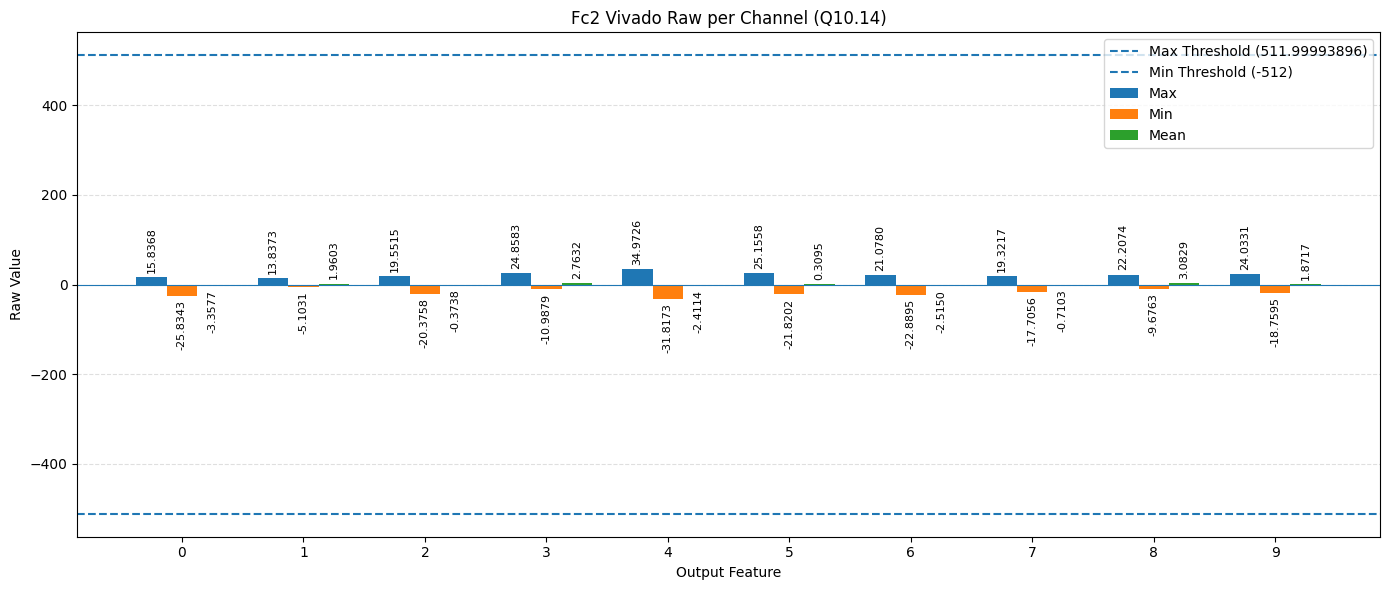

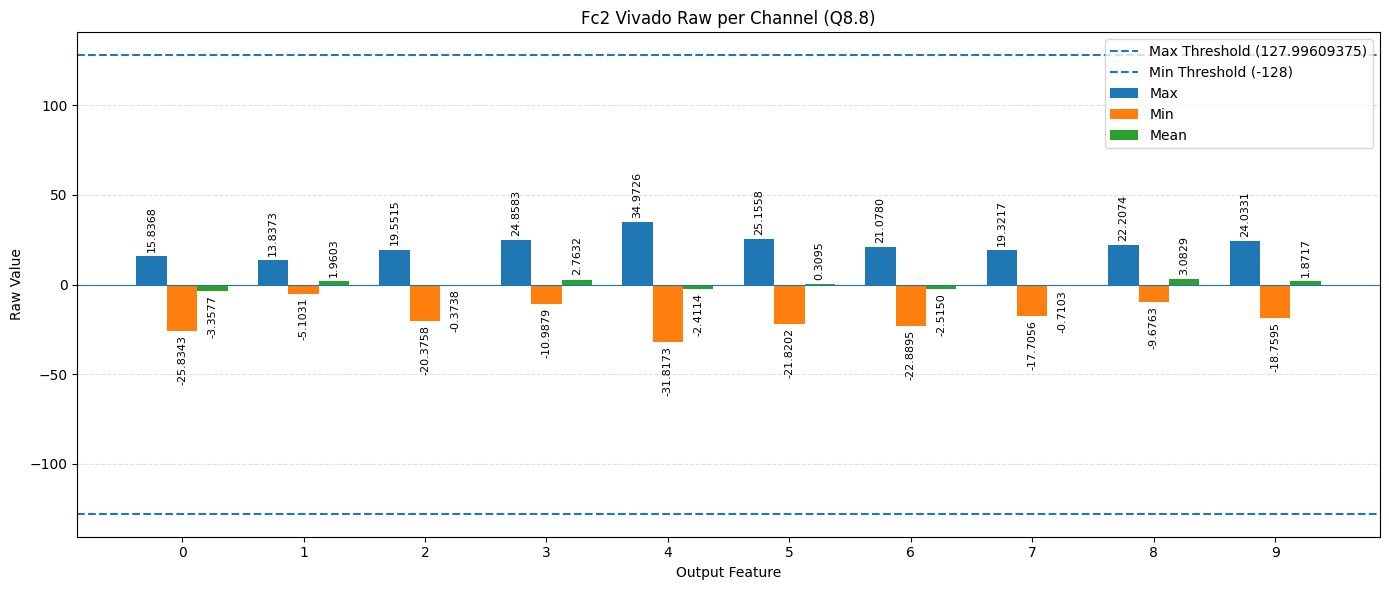

In [43]:
fc2_vivado_feature_raw = load_result_from_vivad_txt(
    "./sim-txt/fc2_raw.txt",
    row_bit=450,
    data_bit=45,
    fract_bit=28,
    total_bit=45
)

print(fc2_vivado_feature_raw.shape)

fc2_raw_vivado_ref = vivado_refrence_maker(
    fc2_vivado_feature_raw, 
    total_pixel_num=1,
    out_ch=10,
    ch_in_row=10
)

print(len(fc2_raw_vivado_ref), fc2_raw_vivado_ref[0].shape)

fc2_max, fc2_min, fc2_mean = create_treshold_vector_data(fc2_raw_vivado_ref)

print(fc2_max.shape, fc2_min.shape, fc2_mean.shape)

plot_raw_treshold(
    fc2_max,
    fc2_min,
    fc2_mean,
    title="Fc2 Vivado Raw per Channel (Q10.14)",
    max_treshold=511.99993896,
    min_treshold=-512,
    xlabel="Output Feature",
    ylabel="Raw Value"
)

plot_raw_treshold(
    fc2_max,
    fc2_min,
    fc2_mean,
    title="Fc2 Vivado Raw per Channel (Q8.8)",
    max_treshold=127.99609375,
    min_treshold=-128,
    xlabel="Output Feature",
    ylabel="Raw Value"
)

## Argmax Results Accuracy

In [44]:
def argmax_pred(x):
    fc2 = model_fc2_predict(x)
    return np.argmax(fc2)

In [45]:
predictions = []

for i in range(1000):
    x = x_all_data[i]
    pred = argmax_pred(x)
    predictions.append(pred)

predictions = np.array(predictions)

predictions.shape

(1000,)

In [46]:
Y_test_grouped.shape

(1000,)

In [47]:
python_accuracy = (predictions == Y_test_grouped) * 1
python_accuracy = python_accuracy.sum() / python_accuracy.shape[0]

In [48]:
print(f"Python Refrence Accuracy: {python_accuracy.item() * 100}%")

Python Refrence Accuracy: 96.6%


In [49]:
class_vivado_output = load_result_from_vivad_txt(
    "./sim-txt/argmax_prediction.txt",
    row_bit=4,
    data_bit=4,
    fract_bit=0,
    total_bit=4,
    is_signed_bit=False
)

print(class_vivado_output.shape)
class_vivado_output = class_vivado_output.reshape(-1)
print(class_vivado_output.shape)

(1000, 1)
(1000,)


In [50]:
vivado_accuracy_comapred_python_refrence = (predictions == class_vivado_output) * 1
vivado_accuracy_comapred_python_refrence = vivado_accuracy_comapred_python_refrence.sum() / vivado_accuracy_comapred_python_refrence.shape[0]

print(f"Vivado Refrence Accuracy Relative to Python Refrence: {vivado_accuracy_comapred_python_refrence.item() * 100}%")

Vivado Refrence Accuracy Relative to Python Refrence: 100.0%


In [51]:
vivado_accuracy_comapred_ground_truth = (predictions == Y_test_grouped) * 1
vivado_accuracy_comapred_ground_truth = vivado_accuracy_comapred_ground_truth.sum() / vivado_accuracy_comapred_ground_truth.shape[0]

print(f"Vivado Refrence Accuracy Relative to Actual Label: {vivado_accuracy_comapred_ground_truth.item() * 100}%")

Vivado Refrence Accuracy Relative to Actual Label: 96.6%
